# BDC Satria Data 2026 - v3 - ConvNeXtV2 pada Data Train Bersih (Single Model, Tanpa Ensemble)

Notebook eksplorasi v3 untuk klasifikasi citra sampah 3 kelas: **0=Recyclable, 1=Electronic, 2=Organic** (juknis SS4). Metrik kompetisi: **Macro-averaged F1-Score**. Notebook ini berdiri sendiri: **satu model, TANPA ensemble/averaging antar arsitektur/blending/stacking** (keputusan final tim, mengikuti pola dua notebook finalis DAC FindIT `ref/findit-v17.ipynb` dan `ref/ver34_clean_end_to_end.ipynb` yang keduanya single-model di jalur final).

**Dokumentasi backbone (wajib, juknis SS5):**
- Model: `convnextv2_base.fcmae_ft_in22k_in1k` dari pustaka `timm` (ConvNeXtV2-Base, 87.7M parameter).
- Pretraining: self-supervised FCMAE lalu supervised fine-tune ImageNet-22k -> ImageNet-1k. Bobot publik di HF Hub (tanpa token) dan **tidak pernah dilatih dengan data train/test kompetisi ini**; panitia mengonfirmasi pretrained publik non-ImageNet pun sah selama di-fine-tune pada Data Latih.
- Mode pemakaian: **full fine-tune** (epoch pertama warm-up head, backbone beku).

**Konteks dan dasar keputusan (kronologi angka):**
1. v1 ConvNeXtV2-Base di data ASLI: OOF pooled **0.9818**. v2 MaxViT-Base: OOF **0.9830**.
2. Analisis `oof_top_errors.csv` v2 (murni train-side): 84.5% top error adalah confusion Recyclable<->Organic; review manual tim menemukan sebagian adalah **label train yang salah**. 111 file di-relabel manual (legalitas dikonfirmasi panitia; log keputusan di `review_queue.csv`).
3. Ablation 1-fold arsitektur v1 di data BERSIH: fold 0 macro F1 **0.9810 -> 0.9847** (tanpa TTA) dan **0.9815 -> 0.9839** (TTA). Sinyal bersih data > sinyal ganti arsitektur.
4. Keputusan arsitektur ConvNeXtV2 (bukan yang lain) berbasis bukti gabungan: DECMCV (arXiv 2503.02241) ConvNeXt encoding menang atas ViT di 2 dataset waste; benchmark Garbage Dataset (arXiv 2602.10500) CNN modern unggul dan **arsitektur >> resolusi input** (384px gain <1%); empiris sendiri v1/v2 konsisten >= 0.98 sementara DINOv3 tim lain ~0.96.

**Apa yang baru di v3 (dibanding resep ablation data-bersih), dan dasarnya:**
1. **Mixup/CutMix di GPU** (p=0.5, alpha 0.2/1.0), terbukti di v2 menekan gap overfit tanpa membebani DataLoader.
2. **Greedy model soup per fold** (arXiv 2603.02181): rata-rata bobot subset checkpoint top-K dipilih greedy berdasarkan val macro F1. Aman untuk ConvNeXtV2 (LayerNorm, bukan BatchNorm); worst case = best single checkpoint; hasil akhir tetap SATU model dengan biaya inferensi satu model.
3. **Gradient clipping 1.0** (resep arXiv 2603.02181 dan template referensi; stabilisasi murah).
4. **RandomVerticalFlip** pada augmentasi train: objek sampah tidak punya orientasi kanonik (Sayem et al., NCA 2025 memakai h+v flip di domain waste). Foto test juga campuran orientasi bebas.
5. **Layer-wise LR decay (LLRD)** tersedia sebagai toggle eksplorasi (`CFG.USE_LLRD`), default OFF supaya run pertama comparable dengan referensi ablation; lihat Catatan Operasional untuk protokol run B.
6. **Logging F1 per kelas per epoch** dan **Grad-CAM audit** pada error Recyclable<->Organic (arXiv 2505.16513: model sortir cenderung belajar bentuk/warna/background, bukan material; perlu diaudit, bukan diasumsikan).
7. Fold **di-recompute fresh** di data bersih (StratifiedKFold 5, seed 42). Karena v3 tidak diensemble dengan siapa pun, fold TIDAK perlu identik v1/v2 (aturan fold-identik hanya untuk eksperimen yang OOF-nya digabung).

**Yang sengaja TIDAK dipakai, dengan alasan:** S2-FracMix (arXiv 2606.25784: gain utama di robustness/corruption, bukan clean accuracy; butuh library fraktal eksternal; mixup/cutmix standar sudah terbukti di v2), GTTA (arXiv 2507.01347: tahap distillation-nya = test-time adaptation, melanggar juknis SS5; varian ensemble-only legal tapi biaya >> manfaat di rezim error 1.6%), resolusi 384 (arXiv 2602.10500), ensemble v1+v2 (keputusan final no-ensemble).

**Aturan kompetisi yang dijaga notebook ini:** data test HANYA untuk prediksi akhir (juknis SS5); tanpa data citra berlabel eksternal; `ref/manual_labeling.csv` tidak pernah dibuka/dibaca/direferensikan; submission mengikuti template persis, nama file kode kelompok `submission_SD2026040000412.csv`.

**Alur**: 0) Setup -> 1) Verifikasi struktur & data bersih -> 2) EDA & cleaning pipeline -> 3) Fold fresh -> 4) Dataset & augmentasi -> 5) Model & optimizer -> 6) Training fold 0 + soup -> 7) Evaluasi & referensi -> 8) Submission -> 9) Analisis error + Grad-CAM.

## 0. Setup & Konfigurasi

Target utama notebook ini **lokal Alienware m15 R7 (Windows 11, CUDA)**; tetap kompatibel Kaggle (deteksi otomatis) dan Mac MPS (smoke test). Hardware TIDAK diasumsikan: cell berikut memverifikasi `torch.cuda.is_available()`, nama GPU, dan VRAM, lalu menyetel batch size/grad accumulation secara adaptif (VRAM < 10GB -> batch 16 + accum 2, batch efektif tetap 32).

`SMOKE_TEST=True` menjalankan seluruh pipeline pada subset kecil untuk verifikasi end-to-end. Run sebenarnya: `SMOKE_TEST=False`, jalankan dari root project (folder yang berisi `train/`, `test/`, `submission.csv`), Run All.

**Kalau dijalankan di Kaggle, baca ini dulu:**
- Dataset yang di-attach **WAJIB versi BERSIH terbaru** (hasil cleaning manual 111 relabel), yaitu yang distribusi kelasnya cocok dengan `CFG.EXPECTED_CLASS_COUNTS`. Dataset lama pra-cleaning akan **dihentikan fail-fast** oleh guard versi data di bagian 1. Itu **perilaku yang benar, bukan bug**: hasil v3 hanya sah di data bersih. Upload folder `train/` versi bersih sebagai Kaggle Dataset baru (atau versi baru dari dataset lama) SEBELUM commit notebook ini.
- Root dataset dicari otomatis di `/kaggle/input` secara recursive (`submission.csv` + `train/` + `test/` dalam satu folder), jadi slug/kedalaman path dataset boleh berubah tanpa mengedit kode. Yang tidak boleh berubah adalah isinya.
- Kaggle T4x2 melaporkan 2 GPU, tetapi v3 **sengaja hanya memakai 1 GPU** (`nn.DataParallel` dilarang permanen sejak v1: leak RAM lewat broadcast parameter). Resep dan batch efektif tidak berubah karenanya.

In [1]:
import copy
import glob
import hashlib
import math
import os
import platform
import random
import signal
import time
from contextlib import nullcontext
from datetime import date
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from timm.data import resolve_model_data_config
from torch import nn
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms
from tqdm.auto import tqdm

Image.MAX_IMAGE_PIXELS = None  # data kompetisi (trusted); foto besar jangan dianggap decompression bomb


def seed_everything(seed: int = 42, deterministic: bool = True):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic  # benchmark aktif = autotune conv, jauh lebih cepat


def rss_gb():
    """RSS proses saat ini dalam GB, untuk observability RAM. Linux via /proc, Windows/Mac via psutil."""
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS:"):
                    return int(line.split()[1]) / 1024 ** 2
    except Exception:
        pass
    try:
        import psutil
        return psutil.Process().memory_info().rss / 1024 ** 3
    except Exception:
        return float("nan")


# Verifikasi hardware SEBELUM asumsi apa pun (jangan hardcode nama GPU dari catatan sesi lain)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
N_GPUS = torch.cuda.device_count()
GPU_VRAM_GB = 0.0
print("torch :", torch.__version__, "| timm :", timm.__version__, "| platform:", platform.system())
print("device:", DEVICE, "| jumlah GPU CUDA:", N_GPUS)
for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    GPU_VRAM_GB = max(GPU_VRAM_GB, props.total_memory / 1024 ** 3)
    print(f"  GPU {i}: {props.name} | {props.total_memory / 1024 ** 3:.1f} GB VRAM")
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True  # Ampere: matmul tf32, aman untuk training vision
    torch.backends.cudnn.allow_tf32 = True

torch : 2.10.0+cu128 | timm : 1.0.26 | platform: Linux
device: cuda | jumlah GPU CUDA: 2
  GPU 0: Tesla T4 | 14.6 GB VRAM
  GPU 1: Tesla T4 | 14.6 GB VRAM


In [2]:
def running_on_kaggle() -> bool:
    return Path("/kaggle/input").exists() or bool(os.getenv("KAGGLE_KERNEL_RUN_TYPE"))


ON_KAGGLE = running_on_kaggle()
# Path dataset v1/v2: dicoba lebih dulu, TAPI tidak pernah diasumsikan ada (slug/kedalaman bisa berubah)
KAGGLE_DATA_ROOT = Path("/kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset")


def is_data_root(p) -> bool:
    """Root data valid = submission.csv + subfolder train/ + test/ sekaligus dalam satu folder."""
    p = Path(p)
    return (p / "submission.csv").is_file() and (p / "train").is_dir() and (p / "test").is_dir()


def resolve_kaggle_data_root() -> Path:
    """Cari root dataset di /kaggle/input tanpa mengasumsikan kedalaman path.

    Pelajaran lessons.md 2026-07-13 (kejadian ke-2): glob '*' TUNGGAL gagal begitu path Kaggle
    nested lebih dalam, dan pola "kalau tidak ketemu pakai yang ada saja" membuat bug lolos tanpa
    gagal keras. Jadi: coba path lama dulu, lalu '**' + recursive=True dengan filter eksplisit
    (is_data_root, bukan asumsi nama folder), dan STOP kalau hasilnya bukan TEPAT SATU kandidat.
    Notebook tidak pernah menebak dataset mana yang dimaksud.
    """
    if is_data_root(KAGGLE_DATA_ROOT):
        print("Root dataset Kaggle: path known-good v1/v2 dipakai apa adanya.")
        return KAGGLE_DATA_ROOT
    cands = sorted({str(Path(p).parent)
                    for p in glob.glob("/kaggle/input/**/submission.csv", recursive=True)
                    if is_data_root(Path(p).parent)})
    assert cands, (
        "Dataset kompetisi TIDAK ditemukan di /kaggle/input. Attach dataset yang berisi "
        "submission.csv + folder train/ + test/ (Add Input), lalu jalankan ulang. "
        f"Path yang dicoba pertama: {KAGGLE_DATA_ROOT}")
    assert len(cands) == 1, (
        f"Ada {len(cands)} kandidat root dataset di /kaggle/input: {cands}. AMBIGU, notebook tidak menebak "
        "(salah pilih = training di data versi lama). Detach yang tidak dipakai, atau set "
        "KAGGLE_DATA_ROOT langsung ke root yang benar lalu jalankan ulang cell ini.")
    print("Root dataset Kaggle ditemukan via pencarian recursive:", cands[0])
    return Path(cands[0])


KAGGLE_DATA_ROOT_RESOLVED = resolve_kaggle_data_root() if ON_KAGGLE else None


class CFG:
    SEED = 42
    RUN_NAME = "v3_convnext_clean"
    GROUP_CODE = "SD2026040000412"  # kode kelompok; nama file submission = submission_<GROUP_CODE>.csv

    ON_KAGGLE = ON_KAGGLE
    DATA_ROOT = KAGGLE_DATA_ROOT_RESOLVED if ON_KAGGLE else Path.cwd()
    OUTPUT_ROOT = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
    TRAIN_DIR = DATA_ROOT / "train"
    TEST_DIR = DATA_ROOT / "test"
    TEMPLATE_PATH = DATA_ROOT / "submission.csv"
    EXP_DIR = OUTPUT_ROOT / "experiments" / RUN_NAME
    LOG_PATH = OUTPUT_ROOT / "experiments" / "EXPERIMENTS_LOG.md"
    SUBMISSION_DIR = OUTPUT_ROOT / "outputs"

    # Mapping resmi juknis SS4, jangan diubah
    LABEL_NAMES = {0: "Recyclable", 1: "Electronic", 2: "Organic"}
    NUM_CLASSES = 3

    # Data train SUDAH melalui cleaning manual (111 relabel, log di review_queue.csv).
    # Guard versi data: full run WAJIB jalan di data bersih ini, bukan salinan lama.
    EXPECTED_CLASS_COUNTS = {"0_Recyclable": 9999, "1_Electronic": 3961, "2_Organic": 12567}
    ALLOW_DATA_DRIFT = False  # True HANYA kalau sadar sedang memakai versi data lain (catat di log!)

    MODEL_ID = "convnextv2_base.fcmae_ft_in22k_in1k"
    IMG_SIZE = 224
    DROP_PATH_RATE = 0.1

    # Referensi pembanding (angka dari EXPERIMENTS_LOG / CONTEXT.md; fold komposisi ablation
    # memakai penamaan file Kaggle sehingga perbandingan fold-0 bersifat APPROXIMATE, bukan exact)
    REF_V1_OOF = 0.9818
    REF_V2_OOF = 0.9830
    REF_ABLATION_FOLD0_NO_TTA = 0.9847
    REF_ABLATION_FOLD0_TTA = 0.9839

    # Training (resep inti = ablation data-bersih yang terbukti: v1 arch, epoch 15, patience 3)
    N_FOLDS = 5
    TRAIN_FOLDS = [0, 1, 2, 3, 4]        # eksplorasi lokal 1 fold; full OOF: [0, 1, 2, 3, 4]
    EPOCHS = 15
    BATCH_SIZE = 32          # diturunkan otomatis ke 16 + accum 2 bila VRAM < 10GB (cell ini, bawah)
    GRAD_ACCUM_STEPS = 1
    NUM_WORKERS = 4          # dioverride di bawah sesuai platform
    BACKBONE_LR = 4e-5
    HEAD_LR = 4e-4
    WEIGHT_DECAY = 1e-4
    FREEZE_BACKBONE_EPOCHS = 1
    EARLY_STOPPING_PATIENCE = 3
    GRAD_CLIP_NORM = 1.0     # baru di v3 (resep arXiv 2603.02181 dan seluruh template referensi)
    FOCAL_GAMMA = 2.0
    LABEL_SMOOTHING = 0.05
    USE_VAL_TTA = True       # metrik seleksi epoch konsisten dengan kondisi inferensi (pola ver34)

    # Toggle eksplorasi run B: layer-wise LR decay (timm create_optimizer_v2).
    # Default OFF supaya run A comparable dengan referensi ablation 0.9847.
    USE_LLRD = False
    LLRD_BASE_LR = 4e-4      # LR head; tiap level ke bawah dikali LAYER_DECAY
    LAYER_DECAY = 0.9

    # Augmentasi: identik v1 + vertical flip (baru v3, justifikasi domain di bagian 4)
    USE_VFLIP = True

    # Mixup/CutMix di GPU (terbukti di v2; MIX_PROB=0 menonaktifkan total)
    MIX_PROB = 0.5
    MIXUP_ALPHA = 0.2
    CUTMIX_ALPHA = 1.0

    # Greedy model soup per fold (arXiv 2603.02181); worst case = best single checkpoint
    USE_GREEDY_SOUP = True
    SOUP_TOPK = 5            # epoch 15 memberi pool kandidat lebih besar dari v2 (top-4 @ epoch 10)

    HEARTBEAT_EVERY_BATCH = 50
    DECODE_TIMEOUT_S = 20
    CUDNN_DETERMINISTIC = False
    RESIZE_MP_THRESHOLD = 8_000_000
    RESIZE_MAX_SIDE = 1024
    MAX_DECODE_SIDE = 1024
    USE_DATA_PARALLEL = False  # keputusan final v1 (memory leak broadcast DataParallel di T4x2 Kaggle);
                               # JANGAN dinyalakan. maybe_data_parallel() meng-assert flag ini tetap False.
    CHANNELS_LAST = True       # conv net + AMP: layout NHWC lebih cepat di GPU RTX/T4

    SMOKE_TEST = False
    SMOKE_PER_CLASS = 40
    SMOKE_TEST_IMAGES = 64


IS_LOCAL_WIN_MAC = platform.system() in ("Windows", "Darwin") and not ON_KAGGLE

# Batch adaptif: RTX 3070 Ti laptop (8GB) tidak muat batch 32 fp16 ConvNeXtV2-Base dengan aman
if DEVICE.type == "cuda" and GPU_VRAM_GB < 10:
    CFG.BATCH_SIZE = 16
    CFG.GRAD_ACCUM_STEPS = 2
    print(f"VRAM {GPU_VRAM_GB:.1f}GB < 10GB: BATCH_SIZE=16, GRAD_ACCUM_STEPS=2 (batch efektif tetap 32)")

# Worker: Windows/mac spawn butuh dataset di modul terpisah (bdc_lib_v3.py, bagian 4);
# lokal CUDA penuh pakai worker banyak, smoke lokal pakai 0 (aman untuk spawn di sesi interaktif)
if CFG.SMOKE_TEST:
    CFG.NUM_WORKERS = 0 if IS_LOCAL_WIN_MAC else 2
elif ON_KAGGLE:
    CFG.NUM_WORKERS = 4
else:
    CFG.NUM_WORKERS = min(8, max(2, (os.cpu_count() or 4) // 2))

# pin_memory: ON untuk CUDA lokal (RAM 32GB longgar); OFF di Kaggle (suspek leak, pelajaran v1) dan MPS
PIN_MEMORY = DEVICE.type == "cuda" and not ON_KAGGLE

if CFG.SMOKE_TEST:
    CFG.TRAIN_FOLDS = [0]
    CFG.EPOCHS = 2  # 2 epoch supaya jalur soup (>= 2 kandidat checkpoint) ikut teruji
    CFG.BATCH_SIZE = 8
    CFG.GRAD_ACCUM_STEPS = 1

_hint = ("Di Kaggle: pastikan dataset kompetisi sudah di-attach (Add Input)."
         if ON_KAGGLE else "Jalankan notebook dari root project (sejajar folder train/ dan test/).")
assert CFG.TRAIN_DIR.is_dir(), f"Folder train tidak ditemukan: {CFG.TRAIN_DIR}\n{_hint}"
assert CFG.TEST_DIR.is_dir(), f"Folder test tidak ditemukan: {CFG.TEST_DIR}\n{_hint}"
assert CFG.TEMPLATE_PATH.is_file(), f"Template submission tidak ditemukan: {CFG.TEMPLATE_PATH}"

CFG.EXP_DIR.mkdir(parents=True, exist_ok=True)
CFG.SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(CFG.SEED, deterministic=CFG.CUDNN_DETERMINISTIC)
print("ENV :", "Kaggle" if ON_KAGGLE else "lokal")
print("DATA:", CFG.DATA_ROOT)
print("OUT :", CFG.OUTPUT_ROOT)
print("MODE:", "SMOKE_TEST (subset kecil, bukan hasil eksperimen)" if CFG.SMOKE_TEST else "FULL RUN")
print(f"batch={CFG.BATCH_SIZE} x accum={CFG.GRAD_ACCUM_STEPS} | workers={CFG.NUM_WORKERS} | pin_memory={PIN_MEMORY}")
print(f"LLRD={'ON (base_lr %.0e, decay %.2f)' % (CFG.LLRD_BASE_LR, CFG.LAYER_DECAY) if CFG.USE_LLRD else 'off (dua grup LR ' + f'{CFG.BACKBONE_LR:.0e}/{CFG.HEAD_LR:.0e})'}")

Root dataset Kaggle ditemukan via pencarian recursive: /kaggle/input/bdc-2026-waste-classification-dataset
ENV : Kaggle
DATA: /kaggle/input/bdc-2026-waste-classification-dataset
OUT : /kaggle/working
MODE: FULL RUN
batch=32 x accum=1 | workers=4 | pin_memory=False
LLRD=off (dua grup LR 4e-05/4e-04)


### Bobot pretrained

Bobot ConvNeXtV2 diunduh `timm` dari HF Hub saat pertama kali dipakai (publik, tanpa token), lalu tersimpan di cache lokal (`~/.cache/huggingface`). Kalau mesin sudah pernah menjalankan v1/ablation, cache sudah ada dan cell ini lolos tanpa internet.

In [3]:
import urllib.request


def internet_ok(url="https://huggingface.co", timeout=10):
    try:
        urllib.request.urlopen(url, timeout=timeout)
        return True
    except Exception:
        return False


try:
    _probe = timm.create_model(CFG.MODEL_ID, pretrained=True, num_classes=0)
    del _probe
    print("Bobot pretrained tersedia (cache lokal atau unduhan barusan berhasil).")
except Exception as e:
    if internet_ok():
        raise
    raise RuntimeError(
        "Bobot pretrained belum ada di cache dan tidak ada koneksi internet ke huggingface.co. "
        "Nyalakan internet sekali untuk mengunduh bobot, lalu jalankan ulang.") from e

model.safetensors:   0%|          | 0.00/355M [00:00<?, ?B/s]

Bobot pretrained tersedia (cache lokal atau unduhan barusan berhasil).


### Observability

Pelajaran run v1/v2: progress intra-epoch wajib terlihat. Heartbeat print (`flush=True`) tiap 50 batch menampilkan s/iter, RSS RAM (+delta), dan VRAM teralokasi (deteksi dini OOM di GPU 8GB). W&B opsional via env var `WANDB_API_KEY` (di-skip rapi kalau tidak ada; token tidak pernah dicetak).

In [4]:
try:
    import wandb
    WANDB_AVAILABLE = True
except ImportError:
    wandb = None
    WANDB_AVAILABLE = False

WANDB_PROJECT = "bdc-satria-data-2026"


def wandb_login():
    if not WANDB_AVAILABLE:
        print("Paket wandb tidak terinstall, logging W&B nonaktif.")
        return False
    api_key = os.getenv("WANDB_API_KEY")
    if not api_key and CFG.ON_KAGGLE:
        try:
            from kaggle_secrets import UserSecretsClient
            api_key = UserSecretsClient().get_secret("WANDB_API_KEY")
        except Exception as e:
            print("Kaggle Secrets WANDB_API_KEY tidak bisa diambil:", repr(e))
    if not api_key:
        print("WANDB_API_KEY tidak tersedia; logging W&B nonaktif (heartbeat tetap tampil via print).")
        return False
    try:
        wandb.login(key=api_key)
        return True
    except Exception as e:
        print("Login W&B gagal:", repr(e))
        return False


WANDB_ENABLED = wandb_login()
print("W&B:", "AKTIF" if WANDB_ENABLED else "nonaktif")

Kaggle Secrets WANDB_API_KEY tidak bisa diambil: BackendError("Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 125761498 and label WANDB_API_KEY.'], 'error': {'code': 5}, 'wasSuccessful': False}.")
WANDB_API_KEY tidak tersedia; logging W&B nonaktif (heartbeat tetap tampil via print).
W&B: nonaktif


## 1. Verifikasi Struktur Data & Versi Data Bersih

Label tidak diasumsikan: struktur folder discan via kode dan mapping folder->label di-assert terhadap juknis. Tambahan v3: **guard versi data**. Folder `train/` yang benar untuk run ini adalah hasil cleaning manual (10.078 / 3.968 / 12.481; total tetap 26.527 karena cleaning murni relabel/move, zero delete). Full run pada distribusi lain dihentikan fail-fast supaya tidak ada hasil yang diam-diam berasal dari data versi lama.

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_dirs = sorted([p for p in CFG.TRAIN_DIR.iterdir() if p.is_dir()])
assert class_dirs, f"Tidak ada subfolder kelas di {CFG.TRAIN_DIR}"

dir_mapping = {}
for d in class_dirs:
    code_str, _, name = d.name.partition("_")
    assert code_str.isdigit() and name, f"Nama subfolder tidak berpola '<kode>_<NamaKelas>': {d.name}"
    dir_mapping[int(code_str)] = (name, d)

assert set(dir_mapping) == set(CFG.LABEL_NAMES), \
    f"Kode kelas folder {sorted(dir_mapping)} != juknis {sorted(CFG.LABEL_NAMES)}"
for label_code, (name, _) in dir_mapping.items():
    assert name == CFG.LABEL_NAMES[label_code], (
        f"Nama kelas folder '{name}' (kode {label_code}) != juknis '{CFG.LABEL_NAMES[label_code]}'")
print("Mapping folder -> label terverifikasi sesuai juknis:", {k: v[0] for k, v in sorted(dir_mapping.items())})

train_rows = []
per_dir_counts = {}
for label_code, (name, d) in sorted(dir_mapping.items()):
    files = [p for p in sorted(d.iterdir()) if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    per_dir_counts[d.name] = len(files)
    for p in files:
        train_rows.append({"relpath": str(p.relative_to(CFG.DATA_ROOT)), "path": str(p),
                           "class_name": name, "label": label_code})
train_df = pd.DataFrame(train_rows)
print(f"Total gambar train: {len(train_df)} | per folder: {per_dir_counts}")

# Guard versi data: run nyata wajib di data BERSIH pasca-relabel manual
if CFG.SMOKE_TEST:
    print("SMOKE_TEST: guard versi data dilewati (smoke boleh jalan di salinan data mana pun).")
elif per_dir_counts != CFG.EXPECTED_CLASS_COUNTS:
    msg = (f"VERSI DATA TIDAK SESUAI. Ditemukan {per_dir_counts}, diharapkan {CFG.EXPECTED_CLASS_COUNTS} "
           "(train/ hasil cleaning manual 111 relabel). Kemungkinan sedang memakai salinan data lama "
           "(pra-cleaning) atau data sudah di-relabel lagi. Kalau distribusi baru memang disengaja: "
           "update CFG.EXPECTED_CLASS_COUNTS, recompute fold, dan catat di EXPERIMENTS_LOG. "
           "Override sadar: CFG.ALLOW_DATA_DRIFT=True.")
    if CFG.ALLOW_DATA_DRIFT:
        print("PERINGATAN (ALLOW_DATA_DRIFT=True):", msg)
    else:
        raise AssertionError(msg)
else:
    print("Guard versi data LULUS: distribusi kelas cocok dengan data bersih pasca-relabel.")

test_paths = sorted([p for p in CFG.TEST_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS])
subdirs_test = [p for p in CFG.TEST_DIR.iterdir() if p.is_dir()]
assert not subdirs_test, f"Tidak diduga: test/ punya subfolder {subdirs_test}"
test_id_to_path = {}
for p in test_paths:
    assert p.stem.isdigit(), f"Nama file test bukan angka murni: {p.name}"
    tid = int(p.stem)
    assert tid not in test_id_to_path, f"id test duplikat: {tid}"
    test_id_to_path[tid] = p
print(f"Total gambar test : {len(test_id_to_path)} | id min={min(test_id_to_path)} max={max(test_id_to_path)}")
assert set(test_id_to_path) == set(range(1, len(test_id_to_path) + 1)), "id test tidak kontinu 1..N"

Mapping folder -> label terverifikasi sesuai juknis: {0: 'Recyclable', 1: 'Electronic', 2: 'Organic'}
Total gambar train: 26527 | per folder: {'0_Recyclable': 9999, '1_Electronic': 3961, '2_Organic': 12567}
Guard versi data LULUS: distribusi kelas cocok dengan data bersih pasca-relabel.
Total gambar test : 1458 | id min=1 max=1458


In [6]:
template_df = pd.read_csv(CFG.TEMPLATE_PATH)
display(template_df.head(3))
assert list(template_df.columns) == ["id", "predicted"], f"Kolom template tidak sesuai: {list(template_df.columns)}"
assert len(template_df) == len(test_id_to_path), \
    f"Baris template ({len(template_df)}) != jumlah file test ({len(test_id_to_path)})"
assert template_df["id"].is_unique, "id template tidak unik"
assert set(template_df["id"]) == set(test_id_to_path), "id template != id file test"

TEMPLATE_ID_ORDER = template_df["id"].tolist()
print(f"Template OK: {len(TEMPLATE_ID_ORDER)} id | awal {TEMPLATE_ID_ORDER[:5]} | akhir {TEMPLATE_ID_ORDER[-5:]}")

,id,predicted
0,1,NaN
1,2,NaN
2,3,NaN


Template OK: 1458 id | awal [1, 2, 3, 4, 5] | akhir [1454, 1455, 1456, 1457, 1458]


In [7]:
# Saat SMOKE_TEST: pangkas train agar seluruh pipeline terverifikasi cepat.
# Hasil smoke BUKAN hasil eksperimen: tidak dicatat ke EXPERIMENTS_LOG dan tidak menghasilkan submission.
if CFG.SMOKE_TEST:
    sampled_idx = []
    for _, g in train_df.groupby("label"):
        sampled_idx.extend(g.sample(min(len(g), CFG.SMOKE_PER_CLASS), random_state=CFG.SEED).index)
    train_df = train_df.loc[sorted(sampled_idx)].reset_index(drop=True)
    print(f"SMOKE_TEST: train_df dipangkas menjadi {len(train_df)} baris ({CFG.SMOKE_PER_CLASS}/kelas)")
else:
    print("FULL RUN: memakai seluruh train_df:", len(train_df), "baris")

FULL RUN: memakai seluruh train_df: 26527 baris


## 2. EDA & Data Cleaning Pipeline

EDA penuh distribusi resolusi/brightness sudah didokumentasikan di notebook v1 dan tetap berlaku (cleaning murni memindahkan 111 label, bukan menambah/menghapus gambar). Yang ditampilkan ulang di sini: distribusi kelas pasca-cleaning, sampel visual per kelas (sanity bahwa relabel masuk akal), lalu pemeriksaan yang MEMPENGARUHI pipeline: integritas decode, dedup exact, dan pre-resize gambar raksasa.

,count,pct
class_name,,
Recyclable,9999,37.69
Electronic,3961,14.93
Organic,12567,47.37


Imbalance ratio (max/min): 3.17x


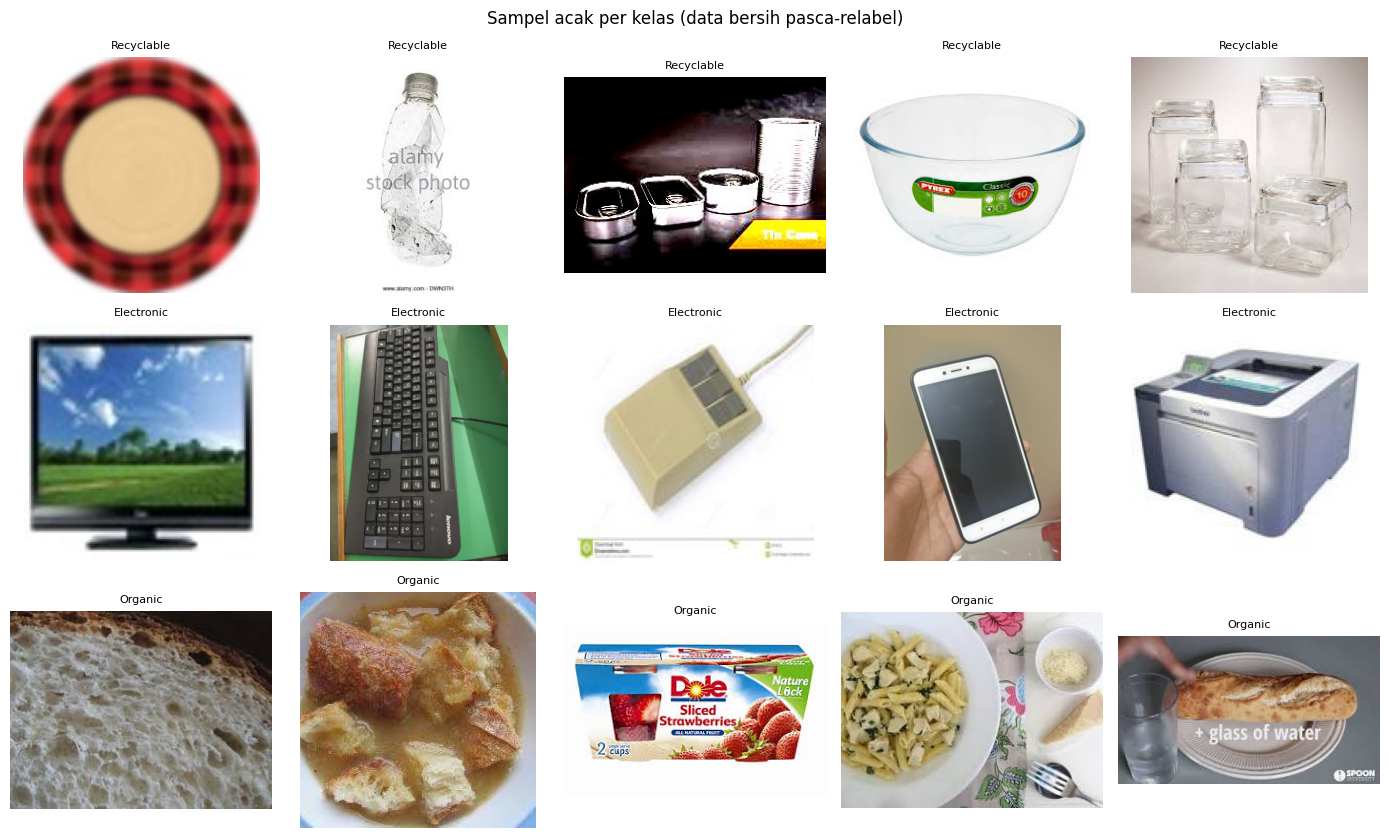

In [8]:
class_counts = train_df["class_name"].value_counts().reindex(
    [CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)])
display(class_counts.to_frame("count").assign(pct=lambda d: (100 * d["count"] / d["count"].sum()).round(2)))
print(f"Imbalance ratio (max/min): {class_counts.max() / class_counts.min():.2f}x")

fig, axes = plt.subplots(3, 5, figsize=(14, 8.5))
rng = np.random.RandomState(CFG.SEED)
for i in range(CFG.NUM_CLASSES):
    sub = train_df[train_df["label"] == i]
    picks = sub.iloc[rng.choice(len(sub), size=min(5, len(sub)), replace=False)]
    for j, (_, r) in enumerate(picks.iterrows()):
        img = Image.open(r["path"])
        img.draft("RGB", (512, 512))
        axes[i, j].imshow(ImageOps.exif_transpose(img).convert("RGB"))
        axes[i, j].set_title(r["class_name"], fontsize=8)
    for j in range(5):
        axes[i, j].axis("off")
plt.suptitle("Sampel acak per kelas (data bersih pasca-relabel)")
plt.tight_layout()
plt.show()

> ### Insights
> Electronic tetap kelas minoritas (~15%, imbalance ~3.2x); `WeightedRandomSampler` + focal alpha `1/sqrt(count)` dipertahankan. Fokus perbaikan v3 justru di pasangan **Recyclable<->Organic**: 84.5% top error OOF v2 ada di pasangan itu, dan review manual membuktikan sebagian adalah label salah yang kini sudah diperbaiki. Sinyal warna adalah pembeda penting R vs O (organik cenderung coklat/hijau tekstur tak beraturan), karena itu ColorJitter tetap `hue=0` dan saturasi moderat: jitter warna berlebihan justru menghapus sinyal kelas (argumen yang sama dipakai ver34 dengan jitter konservatif).

### Integritas file: sha256 + validasi decode (jalur persis DataLoader)

Windows tidak punya `SIGALRM`, jadi timeout decode nonaktif di lokal; risiko decode-hang rendah karena scan v1 di data yang sama tidak menemukan satu pun file hang, dan `Image.draft` membatasi decode file raksasa.

In [9]:
SCAN_VER = 3  # kompatibel cache scan v1/v2 bila tersedia


class DecodeTimeout(Exception):
    pass


def _decode_alarm(signum, frame):
    raise DecodeTimeout()


HAS_SIGALRM = hasattr(signal, "SIGALRM")
if not HAS_SIGALRM:
    print("PERINGATAN: platform tanpa SIGALRM (Windows), timeout decode nonaktif.")


def scan_files(records, cache_path):
    """Satu pass per file: sha256(bytes) + decode penuh + ukuran piksel. Cache (relpath, size, SCAN_VER)."""
    cache = {}
    if Path(cache_path).exists():
        cdf = pd.read_csv(cache_path)
        if "scan_ver" in cdf.columns:
            cache = {(r.relpath, int(r.size_bytes)): dict(r._asdict())
                     for r in cdf.itertuples(index=False) if int(r.scan_ver) == SCAN_VER}
    rows, n_cached = [], 0
    if HAS_SIGALRM:
        signal.signal(signal.SIGALRM, _decode_alarm)
    for rec in tqdm(records, desc=f"scan {Path(cache_path).stem}"):
        p = Path(rec["path"])
        size = p.stat().st_size
        key = (rec["relpath"], size)
        if key in cache:
            rows.append(cache[key])
            n_cached += 1
            continue
        row = {"relpath": rec["relpath"], "size_bytes": size, "sha256": None, "scan_ver": SCAN_VER,
               "decode_ok": False, "width": -1, "height": -1, "error": ""}
        try:
            data = p.read_bytes()
            row["sha256"] = hashlib.sha256(data).hexdigest()
            if HAS_SIGALRM:
                signal.alarm(CFG.DECODE_TIMEOUT_S)
            try:
                with Image.open(BytesIO(data)) as img:
                    row["width"], row["height"] = img.size
                    img.draft("RGB", (CFG.MAX_DECODE_SIDE, CFG.MAX_DECODE_SIDE))
                    decoded = ImageOps.exif_transpose(img).convert("RGB")
            finally:
                if HAS_SIGALRM:
                    signal.alarm(0)
            row["decode_ok"] = True
        except DecodeTimeout:
            row["error"] = f"DecodeTimeout: decode lebih dari {CFG.DECODE_TIMEOUT_S}s, dikeluarkan dari pipeline"
        except Exception as e:
            row["error"] = f"{type(e).__name__}: {e}"[:200]
        rows.append(row)
        cache[key] = row
    pd.DataFrame(list(cache.values())).to_csv(cache_path, index=False)
    out = pd.DataFrame(rows)
    print(f"  {len(out)} file | {n_cached} dari cache | gagal decode/timeout={int((~out['decode_ok'].astype(bool)).sum())}")
    return out


train_scan = scan_files(train_df.to_dict("records"), CFG.EXP_DIR / "scan_train.csv")
test_records = [{"relpath": str(p.relative_to(CFG.DATA_ROOT)), "path": str(p)} for p in test_paths]
test_scan = scan_files(test_records, CFG.EXP_DIR / "scan_test.csv")

scan scan_train:   0%|          | 0/26527 [00:00<?, ?it/s]

  26527 file | 0 dari cache | gagal decode/timeout=0


scan scan_test:   0%|          | 0/1458 [00:00<?, ?it/s]

  1458 file | 0 dari cache | gagal decode/timeout=0


In [10]:
train_scan["decode_ok"] = train_scan["decode_ok"].astype(bool)
test_scan["decode_ok"] = test_scan["decode_ok"].astype(bool)
corrupt_train = train_scan[~train_scan["decode_ok"]]
corrupt_test = test_scan[~test_scan["decode_ok"]]
if len(corrupt_train):
    print("File train corrupt (di-drop dari training):")
    display(corrupt_train)
if len(corrupt_test):
    print("PERHATIAN: file test corrupt, tetap wajib diprediksi; inference memakai fallback gambar hitam:")
    display(corrupt_test)
if corrupt_train.empty and corrupt_test.empty:
    print("Tidak ada file corrupt.")

train_df = train_df.merge(train_scan[["relpath", "sha256", "decode_ok", "width", "height"]],
                          on="relpath", validate="1:1")
n_before = len(train_df)
train_df = train_df[train_df["decode_ok"]].drop(columns=["decode_ok"]).reset_index(drop=True)
print(f"train_df: {n_before} -> {len(train_df)} setelah drop corrupt")

Tidak ada file corrupt.
train_df: 26527 -> 26527 setelah drop corrupt


### Duplikat exact (sha256) dan antrean review

Kebijakan identik v1/v2: duplikat same-label disimpan 1 salinan; grup **mixed-label** dikeluarkan dari training dan masuk antrean review manual; overlap exact train-test hanya dilaporkan (pemanfaatannya di sisi prediksi, bagian 8). Tidak ada relabel/exclude otomatis: keputusan label selalu manusia (pola yang sama dengan cleaning 111 file kemarin).

In [11]:
grp = train_df.groupby("sha256")
group_size = grp["relpath"].transform("size")
n_labels_in_group = grp["label"].transform("nunique")
dup_mask = group_size > 1
mixed_mask = n_labels_in_group > 1

print(f"Grup duplikat exact dalam train: {train_df.loc[dup_mask, 'sha256'].nunique()} grup ({int(dup_mask.sum())} file)")
print(f"  di antaranya mixed-label     : {train_df.loc[mixed_mask, 'sha256'].nunique()} grup ({int(mixed_mask.sum())} file)")

review_df = train_df[mixed_mask].sort_values(["sha256", "relpath"]).copy()
if len(review_df):
    review_df["group_id"] = review_df.groupby("sha256").ngroup()
    review_df["labels_in_group"] = review_df.groupby("sha256")["class_name"].transform(
        lambda s: "|".join(sorted(set(s))))
    review_df["corrected_label"] = ""
review_path = CFG.EXP_DIR / "duplicates_mixed_label_review.csv"
review_df.to_csv(review_path, index=False)
print(f"Antrean review manual disimpan: {review_path} ({len(review_df)} baris)")

n_before = len(train_df)
train_df = train_df[~mixed_mask]
train_df = train_df.sort_values("relpath").drop_duplicates("sha256").reset_index(drop=True)
print(f"train_df: {n_before} -> {len(train_df)} setelah dedup")

test_hashes = set(test_scan.loc[test_scan["decode_ok"], "sha256"])
overlap = train_df[train_df["sha256"].isin(test_hashes)]
print(f"\nOverlap exact train<->test: {len(overlap)} file train identik dengan file test (LAPORAN SAJA di sini).")

Grup duplikat exact dalam train: 62 grup (124 file)
  di antaranya mixed-label     : 1 grup (2 file)
Antrean review manual disimpan: /kaggle/working/experiments/v3_convnext_clean/duplicates_mixed_label_review.csv (2 baris)
train_df: 26527 -> 26464 setelah dedup

Overlap exact train<->test: 97 file train identik dengan file test (LAPORAN SAJA di sini).


### Pre-resize salinan gambar raksasa (>=8MP)

Dipertahankan dari v1 (fix insiden OOM): gambar >=8MP dibuatkan salinan sisi maksimum 1024px di `train_resized/`. File asli **tidak diubah**; `Image.draft` juga terpasang permanen di dataset sebagai pengaman kedua. Fail-fast assertion menghentikan run bila substitusi path gagal.

In [12]:
t_resize = time.time()
big_mask = (train_df["width"].astype(int) * train_df["height"].astype(int)) >= CFG.RESIZE_MP_THRESHOLD
resized_root = CFG.OUTPUT_ROOT / "train_resized"
n_big = int(big_mask.sum())
sample_before = train_df.loc[big_mask, "path"].head(3).tolist()
print(f"pre-resize: {n_big} gambar >= {CFG.RESIZE_MP_THRESHOLD / 1e6:.0f}MP terdeteksi", flush=True)
n_new = 0
for idx in tqdm(train_df.index[big_mask], desc="pre-resize"):
    dst = resized_root / train_df.at[idx, "relpath"]
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        img = Image.open(train_df.at[idx, "path"])
        img.draft("RGB", (CFG.RESIZE_MAX_SIDE, CFG.RESIZE_MAX_SIDE))
        img = ImageOps.exif_transpose(img).convert("RGB")
        img.thumbnail((CFG.RESIZE_MAX_SIDE, CFG.RESIZE_MAX_SIDE), Image.Resampling.LANCZOS)
        if dst.suffix.lower() in {".jpg", ".jpeg"}:
            img.save(dst, quality=95)
        else:
            img.save(dst)
        n_new += 1
    train_df.at[idx, "path"] = str(dst)

if n_big:
    redirected = train_df.loc[big_mask, "path"]
    assert redirected.str.startswith(str(resized_root)).all(), \
        "pre-resize GAGAL: sebagian path masih menunjuk file asli raksasa"
    _missing = [p for p in redirected if not Path(p).is_file()]
    assert not _missing, f"pre-resize GAGAL: {len(_missing)} salinan tidak ada di disk, contoh: {_missing[:3]}"
    with Image.open(redirected.iloc[0]) as _im:
        assert max(_im.size) <= CFG.RESIZE_MAX_SIDE, f"pre-resize GAGAL: salinan masih berukuran {_im.size}"
assert not train_df.loc[~big_mask, "path"].str.startswith(str(resized_root)).any(), \
    "path gambar normal ikut teralihkan, tidak seharusnya"
print(f"pre-resize SELESAI: {n_big} dialihkan ({n_new} baru dibuat) dalam {time.time() - t_resize:.1f}s "
      f"| RSS {rss_gb():.1f}GB", flush=True)

pre-resize: 233 gambar >= 8MP terdeteksi


pre-resize:   0%|          | 0/233 [00:00<?, ?it/s]

pre-resize SELESAI: 233 dialihkan (233 baru dibuat) dalam 35.8s | RSS 1.1GB


## 3. Fold: Recompute Fresh di Data Bersih

`StratifiedKFold(5, shuffle, seed 42)` pada `train_df` terurut `relpath` (deterministik untuk mesin dan versi data yang sama). **Fold sengaja TIDAK disamakan dengan v1/v2**: aturan fold-identik hanya diperlukan bila OOF antar eksperimen mau digabung/diensemble, sedangkan v3 berdiri sendiri (no-ensemble) dan datanya pun sudah berbeda (111 label pindah). Konsekuensi yang diterima sadar: angka fold 0 v3 vs fold 0 ablation adalah perbandingan APPROXIMATE (komposisi fold beda karena penamaan file Kaggle vs lokal), dengan std antar-fold historis sekitar +-0.002 sebagai konteks pembacaan.

In [13]:
skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
train_df["fold"] = -1
for fold, (_, val_idx) in enumerate(skf.split(train_df["relpath"], train_df["label"])):
    train_df.loc[val_idx, "fold"] = fold
assert (train_df["fold"] >= 0).all()

folds_path = CFG.EXP_DIR / "folds.csv"
train_df[["relpath", "class_name", "label", "fold"]].to_csv(folds_path, index=False)
print("Fold assignment disimpan:", folds_path)
ct = pd.crosstab(train_df["fold"], train_df["class_name"])
display(ct)
# Sanity: stratifikasi seimbang (selisih antar fold per kelas maksimal 1)
assert int((ct.max() - ct.min()).max()) <= 1, "Stratifikasi tidak seimbang, ada yang salah di split"
print("Stratifikasi seimbang (selisih maksimum antar fold per kelas <= 1).")

Fold assignment disimpan: /kaggle/working/experiments/v3_convnext_clean/folds.csv


class_name,Electronic,Organic,Recyclable
fold,,,
0,786,2509,1998
1,786,2509,1998
2,786,2509,1998
3,786,2509,1998
4,787,2508,1997


Stratifikasi seimbang (selisih maksimum antar fold per kelas <= 1).


## 4. Dataset, Augmentasi Online, Loss, dan Mixup/CutMix

Augmentasi berbasis PIL identik v1 (RandomResizedCrop 0.65-1.0, HFlip, ColorJitter brightness/contrast agresif `hue=0`, blur nonaktif; parameter sudah teruji 3 run) **plus satu tambahan v3: RandomVerticalFlip(0.5)**. Justifikasi: objek sampah difoto tanpa orientasi kanonik (tergeletak, dari atas, terbalik); benchmark domain waste (Sayem et al., NCA 2025) memakai h+v flip; dan vflip nol biaya CPU (PIL transpose). Regularisasi tambahan tetap di GPU: **Mixup (alpha 0.2) / CutMix (alpha 1.0)** dipilih acak 50:50 dengan peluang `MIX_PROB=0.5` per batch, terbukti di v2 menekan gap overfit (train 0.999 vs val 0.982 di v1). Loss `FocalLossWithSmoothing` alpha `1/sqrt(count)` + `WeightedRandomSampler` (pola ver34, dipertahankan 3 run).

> ### Insights
> S2-FracMix (arXiv 2606.25784) sempat dievaluasi sebagai kandidat augmentasi: label-preserving dan legal, tetapi teorinya sendiri memprediksi gain terbesar di robustness/corruption (bukan clean accuracy), butuh library 400 citra fraktal eksternal, dan menambah beban CPU loader. Di rezim error 1.6% dengan mixup/cutmix yang sudah terbukti di v2, rasio manfaat/risiko tidak menang. Keputusan lama (lessons 2026-07-12 no. 9) dipertahankan.

### Modularisasi dataset (bdc_lib_v3.py)

Modul terpisah supaya kelas dataset picklable oleh DataLoader worker `spawn` (**wajib di Windows** dengan `NUM_WORKERS>0`; ini alasan utama pola `%%writefile` dipertahankan untuk run lokal Alienware).

In [14]:
%%writefile bdc_lib_v3.py
"""Dataset dan transform untuk BDC Satria Data 2026 (v3, data bersih).

Basis identik bdc_lib.py v1; perubahan v3: opsi RandomVerticalFlip pada train transform.
File terpisah dari bdc_lib.py/bdc_lib_v2.py supaya tiga notebook bisa hidup berdampingan.
"""
import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset
from torchvision import transforms


class WasteDataset(Dataset):
    def __init__(self, df, transform, with_target=True, safe_mode=False, img_size=224, max_decode_side=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.with_target = with_target
        self.safe_mode = safe_mode  # True untuk test: file gagal decode -> gambar hitam (tetap wajib diprediksi)
        self.img_size = img_size
        self.max_decode_side = max_decode_side

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        try:
            image = Image.open(row["path"])
            if self.max_decode_side:
                # JPEG: decoder membaca langsung pada resolusi tereduksi; file raksasa TIDAK PERNAH
                # dimuat resolusi penuh ke RAM (terukur v1: 569MB -> 54MB per file 48MP).
                image.draft("RGB", (self.max_decode_side, self.max_decode_side))
            image = ImageOps.exif_transpose(image).convert("RGB")
        except Exception:
            if not self.safe_mode:
                raise
            image = Image.new("RGB", (self.img_size, self.img_size))
        sample = {"image": self.transform(image)}
        if self.with_target:
            sample["target"] = torch.tensor(int(row["label"]), dtype=torch.long)
        return sample


def build_transforms(img_size, mean, std, use_vflip=False):
    """Augmentasi online. Basis identik v1; use_vflip=True menambah RandomVerticalFlip (v3)."""
    train_ops = [
        transforms.RandomResizedCrop(img_size, scale=(0.65, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
    ]
    if use_vflip:
        # Objek sampah tidak punya orientasi kanonik; vflip PIL = transpose, nol biaya interpolasi
        train_ops.append(transforms.RandomVerticalFlip(p=0.5))
    train_ops += [
        # hue=0: konversi warna per gambar mahal di CPU, dan hue adalah sinyal kelas (organik coklat/hijau)
        transforms.RandomApply([transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.25, hue=0.0)], p=0.8),
        # GaussianBlur tetap nonaktif (beban CPU tinggi); regularisasi tambahan ada di mixup/cutmix GPU
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
    train_transform = transforms.Compose(train_ops)
    eval_transform = transforms.Compose([
        transforms.Resize(int(img_size * 1.14)),
        transforms.CenterCrop(img_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    return train_transform, eval_transform


def worker_init_fn(worker_id):
    """1 thread intra-op per worker: cegah oversubscription CPU (pelajaran run v1)."""
    torch.set_num_threads(1)

Writing bdc_lib_v3.py


In [15]:
import importlib

import bdc_lib_v3
importlib.reload(bdc_lib_v3)
from bdc_lib_v3 import WasteDataset, build_transforms, worker_init_fn

print("modul dataset:", bdc_lib_v3.__file__)

# mean/std mengikuti konfigurasi pretrained timm (probe tanpa mengunduh bobot)
probe = timm.create_model(CFG.MODEL_ID, pretrained=False, num_classes=0)
data_cfg = resolve_model_data_config(probe)
MEAN, STD = tuple(data_cfg["mean"]), tuple(data_cfg["std"])
assert data_cfg["input_size"][-1] == CFG.IMG_SIZE, f"Input size model {data_cfg['input_size']} != CFG.IMG_SIZE"
del probe
print("normalisasi:", MEAN, STD)

train_transform, eval_transform = build_transforms(CFG.IMG_SIZE, MEAN, STD, use_vflip=CFG.USE_VFLIP)
print(train_transform)

modul dataset: /kaggle/working/bdc_lib_v3.py
normalisasi: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.65, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomApply(
    p=0.8
    ColorJitter(brightness=(0.6, 1.4), contrast=(0.6, 1.4), saturation=(0.75, 1.25), hue=None)
)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


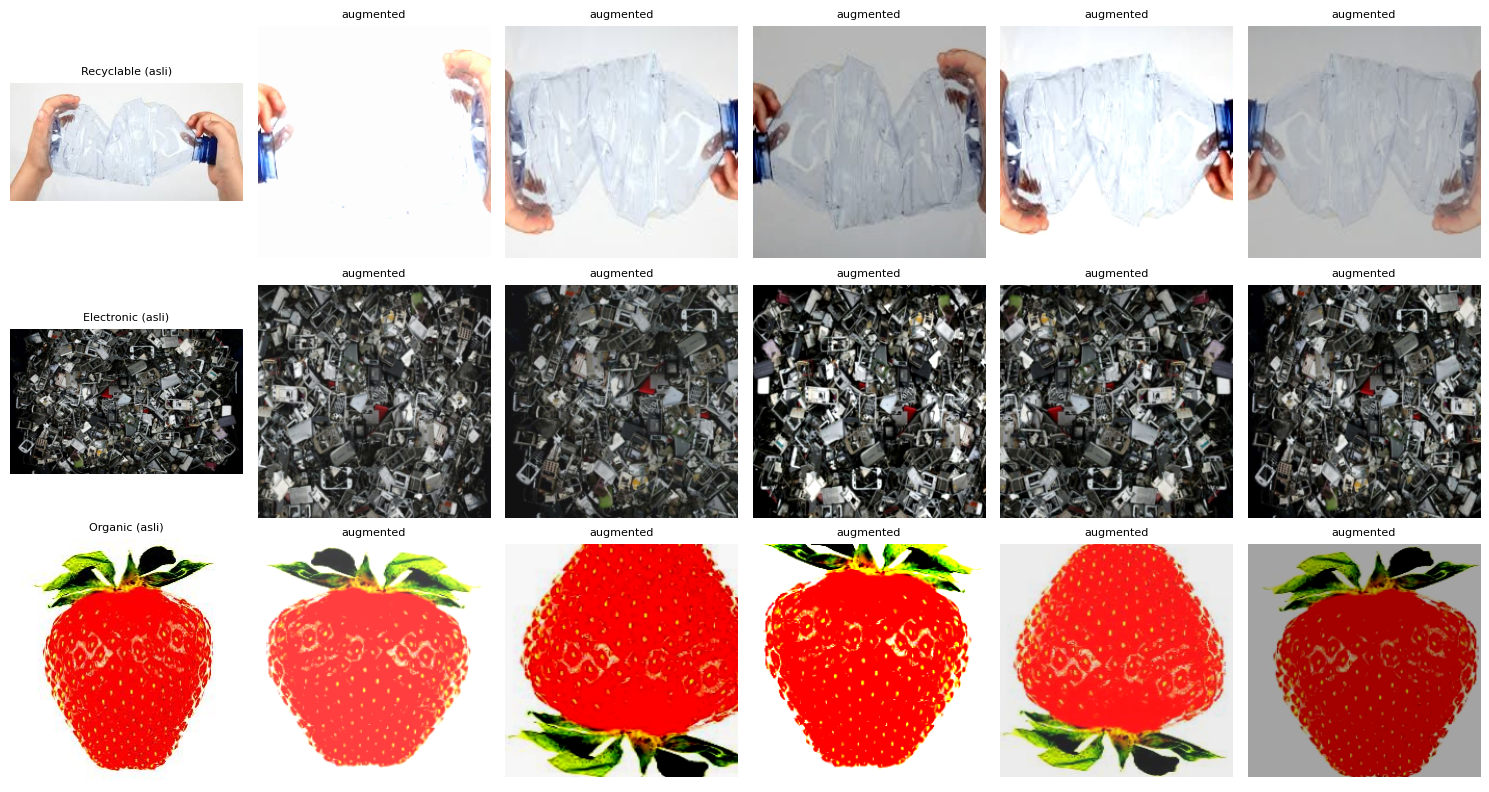

In [16]:
# Sanity check visual augmentasi: 1 gambar per kelas, 5 variasi augmented
viz_tf = transforms.Compose(train_transform.transforms[:-2])  # tanpa ToTensor/Normalize
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for i in range(CFG.NUM_CLASSES):
    row = train_df[train_df["label"] == i].iloc[0]
    img = ImageOps.exif_transpose(Image.open(row["path"])).convert("RGB")
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{row['class_name']} (asli)", fontsize=8)
    for j in range(1, 6):
        axes[i, j].imshow(viz_tf(img))
        axes[i, j].set_title("augmented", fontsize=8)
    for j in range(6):
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

In [17]:
class FocalLossWithSmoothing(nn.Module):
    """Pola ref/ver34_clean_end_to_end.ipynb, identik v1/v2."""

    def __init__(self, num_classes, alpha, gamma, smoothing):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.num_classes = num_classes
        self.alpha = alpha

    def forward(self, inputs, targets):
        with torch.no_grad():
            true_dist = torch.zeros_like(inputs)
            true_dist.fill_(self.smoothing / (self.num_classes - 1))
            true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        log_p = F.log_softmax(inputs, dim=-1)
        p = log_p.exp()
        focal_weight = (1.0 - p).pow(self.gamma)
        focal_weight = focal_weight * self.alpha[targets].view(-1, 1)
        return (-focal_weight * true_dist * log_p).sum(dim=-1).mean()


def build_criterion(fold_train_df):
    counts = fold_train_df["label"].value_counts()
    weights = torch.tensor([1.0 / math.sqrt(counts.get(c, 1)) for c in range(CFG.NUM_CLASSES)],
                           dtype=torch.float32, device=DEVICE)
    weights /= weights.mean()
    return FocalLossWithSmoothing(CFG.NUM_CLASSES, alpha=weights, gamma=CFG.FOCAL_GAMMA,
                                  smoothing=CFG.LABEL_SMOOTHING), weights


def build_sampler(fold_train_df, seed):
    counts = fold_train_df["label"].value_counts().to_dict()
    sample_weights = fold_train_df["label"].map(lambda c: 1.0 / counts[c]).to_numpy(dtype=np.float64).copy()
    gen = torch.Generator()
    gen.manual_seed(seed)
    return WeightedRandomSampler(torch.DoubleTensor(sample_weights), num_samples=len(sample_weights),
                                 replacement=True, generator=gen)


def mixup_cutmix_batch(images, targets):
    """Mixup/CutMix DI GPU setelah batch tiba (nol beban CPU loader).
    Return: images (mungkin dimodifikasi in-place untuk cutmix), dan mix_info=(y_a, y_b, lam) atau None."""
    if CFG.MIX_PROB <= 0 or float(torch.rand(())) > CFG.MIX_PROB or images.size(0) < 2:
        return images, None
    use_cutmix = float(torch.rand(())) < 0.5
    alpha = CFG.CUTMIX_ALPHA if use_cutmix else CFG.MIXUP_ALPHA
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(images.size(0), device=images.device)
    if use_cutmix:
        H, W = images.shape[-2:]
        r = math.sqrt(1.0 - lam)
        cw, ch = int(W * r), int(H * r)
        cx, cy = np.random.randint(W), np.random.randint(H)
        x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
        y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
        if x2 > x1 and y2 > y1:
            images[:, :, y1:y2, x1:x2] = images[perm, :, y1:y2, x1:x2]
            lam = 1.0 - ((x2 - x1) * (y2 - y1) / (W * H))
        else:
            return images, None
    else:
        images = lam * images + (1.0 - lam) * images[perm]
    return images, (targets, targets[perm], lam)

## 5. Model & Optimizer - ConvNeXtV2-Base Full Fine-tune

ConvNeXtV2-Base (pure conv, GRN) dengan head 3 kelas; semua parameter dilatih, kecuali epoch pertama backbone beku (warm-up head, pola v1/ver34). Dua skema optimizer:

- **Default (run A, comparable dengan ablation 0.9847)**: AdamW dua grup, backbone `4e-5`, head `4e-4`, cosine annealing.
- **Eksplorasi (run B, `CFG.USE_LLRD=True`)**: layer-wise LR decay via `timm.optim.create_optimizer_v2(layer_decay=0.9)`; head LR penuh `4e-4`, tiap level di bawahnya dikali 0.9 (stem ~8e-6). Catatan implementasi penting: timm hanya mengisi `lr_scale` per grup dan scheduler bawaan PyTorch mengabaikannya, jadi `lr_scale` **di-bake ke `lr`** sebelum scheduler dibuat (diverifikasi: 38 level LR berbeda, head tetap 4e-4).

Wrapper `AutocastForward`/`unwrap` dipertahankan dari v1 supaya checkpoint bersih dari prefix `module.`/`m.`. `maybe_data_parallel` di v3 **selalu** mengembalikan model apa adanya: bahkan di Kaggle T4x2 yang melaporkan 2 GPU, v3 jalan **single-GPU**. `nn.DataParallel` mem-broadcast parameter tiap step lewat host staging memory dan terbukti bocor RAM di T4x2 (keputusan final v1); di v3 larangan itu di-hardcode, bukan sekadar toggle, dan `CFG.USE_DATA_PARALLEL=False` di-assert supaya tidak ada jalan menyalakannya lagi tanpa sadar. `channels_last` diaktifkan untuk CUDA (layout NHWC lebih cepat untuk conv net dengan AMP di RTX).

In [18]:
def build_model():
    model = timm.create_model(CFG.MODEL_ID, pretrained=True, num_classes=CFG.NUM_CLASSES,
                              drop_path_rate=CFG.DROP_PATH_RATE)
    n_param = sum(p.numel() for p in model.parameters()) / 1e6
    assert 60 < n_param < 110, f"Jumlah parameter {n_param:.1f}M tidak wajar untuk ConvNeXtV2-Base; cek CFG.MODEL_ID"
    return model


def split_param_groups(model):
    head_params = [p for n, p in model.named_parameters() if n.startswith("head.")]
    backbone_params = [p for n, p in model.named_parameters() if not n.startswith("head.")]
    assert head_params, "Head tidak terdeteksi, cek penamaan parameter model"
    return backbone_params, head_params


def set_backbone_trainable(model, trainable):
    for n, p in model.named_parameters():
        if not n.startswith("head."):
            p.requires_grad = trainable


def build_optimizer(model):
    """Dua skema: dua-grup (default, identik v1) atau LLRD (eksplorasi run B)."""
    if CFG.USE_LLRD:
        from timm.optim import create_optimizer_v2
        opt = create_optimizer_v2(model, opt="adamw", lr=CFG.LLRD_BASE_LR,
                                  weight_decay=CFG.WEIGHT_DECAY, layer_decay=CFG.LAYER_DECAY)
        # timm mengisi lr_scale per grup; scheduler torch native mengabaikannya, jadi bake ke lr
        for g in opt.param_groups:
            g["lr"] = g["lr"] * g.get("lr_scale", 1.0)
        lrs = sorted({round(g["lr"], 12) for g in opt.param_groups})
        print(f"optimizer: AdamW LLRD | {len(opt.param_groups)} grup | LR {lrs[0]:.2e} .. {lrs[-1]:.2e}")
        return opt
    backbone_params, head_params = split_param_groups(model)
    opt = torch.optim.AdamW([
        {"params": backbone_params, "lr": CFG.BACKBONE_LR},
        {"params": head_params, "lr": CFG.HEAD_LR},
    ], weight_decay=CFG.WEIGHT_DECAY)
    print(f"optimizer: AdamW dua grup | backbone {CFG.BACKBONE_LR:.0e} | head {CFG.HEAD_LR:.0e}")
    return opt


class AutocastForward(nn.Module):
    """autocast thread-local: dipertahankan dari v1 untuk kompatibilitas (aktif hanya bila DataParallel)."""

    def __init__(self, module):
        super().__init__()
        self.m = module

    def forward(self, x):
        with torch.amp.autocast("cuda", dtype=torch.float16):
            return self.m(x)


def maybe_data_parallel(model):
    """v3 SELALU single-GPU, termasuk di Kaggle T4x2 yang melaporkan 2 GPU.

    Larangan DataParallel di-HARDCODE di sini, bukan dibuat opsional lewat CFG: nn.DataParallel
    mem-broadcast parameter tiap step lewat host staging memory dan bocor RAM di T4x2 Kaggle
    (keputusan final v1, tidak pernah dicabut). CFG.USE_DATA_PARALLEL dipertahankan sebagai
    dokumentasi keputusan dan di-assert, supaya menyalakannya gagal keras, bukan diam-diam jalan.
    """
    assert not CFG.USE_DATA_PARALLEL, (
        "CFG.USE_DATA_PARALLEL harus False: DataParallel bocor RAM di T4x2 (keputusan final v1). "
        "v3 tidak menyediakan jalur multi-GPU.")
    if DEVICE.type == "cuda" and N_GPUS > 1:
        print(f"{N_GPUS} GPU terdeteksi; v3 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).",
              flush=True)
    return model


def unwrap(model):
    if isinstance(model, nn.DataParallel):
        model = model.module
    if isinstance(model, AutocastForward):
        model = model.m
    return model


def to_device(model):
    model = model.to(DEVICE)
    if CFG.CHANNELS_LAST and DEVICE.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    return model


_m = build_model()
bb, hd = split_param_groups(_m)
print(f"total params    : {sum(p.numel() for p in _m.parameters()) / 1e6:.1f}M")
print(f"backbone params : {sum(p.numel() for p in bb) / 1e6:.1f}M | head params: {sum(p.numel() for p in hd) / 1e6:.3f}M")
del _m

total params    : 87.7M
backbone params : 87.7M | head params: 0.005M


In [19]:
def run_epoch(model, loader, criterion=None, optimizer=None, scaler=None, use_tta=False, desc="",
              train_mix=False):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    losses, all_targets, all_preds, all_probs = [], [], [], []
    if is_train:
        optimizer.zero_grad(set_to_none=True)
    t_start = time.time()
    rss_start = rss_gb()
    progress = tqdm(loader, desc=desc or ("train" if is_train else "valid"), leave=False)
    for step, batch in enumerate(progress, start=1):
        images = batch["image"].to(DEVICE, non_blocking=True)
        if CFG.CHANNELS_LAST and DEVICE.type == "cuda":
            images = images.to(memory_format=torch.channels_last)
        targets = batch["target"].to(DEVICE, non_blocking=True) if "target" in batch else None
        mix_info = None
        if is_train and train_mix and targets is not None:
            images, mix_info = mixup_cutmix_batch(images, targets)
        amp_ctx = torch.amp.autocast("cuda", dtype=torch.float16) if DEVICE.type == "cuda" else nullcontext()
        with torch.set_grad_enabled(is_train), amp_ctx:
            logits = model(images)
            if use_tta and not is_train:
                logits = 0.5 * (logits + model(torch.flip(images, dims=[3])))
            if criterion is not None and targets is not None:
                if mix_info is not None:
                    y_a, y_b, lam = mix_info
                    loss = lam * criterion(logits, y_a) + (1.0 - lam) * criterion(logits, y_b)
                else:
                    loss = criterion(logits, targets)
            else:
                loss = None
        if is_train:
            scaled = loss / CFG.GRAD_ACCUM_STEPS
            if scaler is not None:
                scaler.scale(scaled).backward()
                if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
                    if CFG.GRAD_CLIP_NORM:
                        scaler.unscale_(optimizer)
                        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP_NORM)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
            else:
                scaled.backward()
                if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
                    if CFG.GRAD_CLIP_NORM:
                        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP_NORM)
                    optimizer.step()
                    optimizer.zero_grad(set_to_none=True)
        probs = torch.softmax(logits.float(), dim=1).detach().cpu().numpy()
        all_probs.append(probs)
        all_preds.extend(probs.argmax(axis=1).tolist())
        if loss is not None:
            losses.append(loss.item())
            # catatan: pada batch ter-mix, target metrik memakai y asli (train F1 = indikator kasar saja)
            all_targets.extend(targets.cpu().numpy().tolist())
            progress.set_postfix(loss=f"{np.mean(losses):.4f}")
        if step % CFG.HEARTBEAT_EVERY_BATCH == 0 or step == len(loader):
            elapsed = time.time() - t_start
            pct = 100.0 * step / max(len(loader), 1)
            _rss_now = rss_gb()
            _vram = (f" | VRAM {torch.cuda.max_memory_allocated() / 1024 ** 3:.1f}GB"
                     if DEVICE.type == "cuda" else "")
            print(f"[hb] {desc or 'epoch'}: batch {step}/{len(loader)} ({pct:.0f}%) | "
                  f"{elapsed / step:.2f}s/iter | RSS {_rss_now:.1f}GB (delta {_rss_now - rss_start:+.1f}GB){_vram}",
                  flush=True)
            if WANDB_ENABLED and wandb.run is not None:
                wandb.log({"hb/pct": pct, "hb/sec_per_iter": elapsed / step, "hb/batch": step,
                           "hb/rss_gb": _rss_now})
    out = {"loss": float(np.mean(losses)) if losses else float("nan"),
           "preds": np.array(all_preds),
           "probs": np.concatenate(all_probs) if all_probs else None}
    if all_targets:
        out["targets"] = np.array(all_targets)
        out["macro_f1"] = float(f1_score(out["targets"], out["preds"], average="macro"))
        out["per_class_f1"] = f1_score(out["targets"], out["preds"], average=None,
                                       labels=list(range(CFG.NUM_CLASSES)))
    return out

## 6. Training Fold 0 + Greedy Model Soup

`TRAIN_FOLDS=[0]`: eksplorasi lokal satu fold dulu; full 5-fold hanya kalau fold 0 lolos pembacaan (Catatan Operasional). Pantau 10 heartbeat pertama: `s/iter` untuk proyeksi runtime dan `VRAM` (kalau mendekati kapasitas GPU: turunkan `BATCH_SIZE`, naikkan `GRAD_ACCUM_STEPS`).

**Mekanisme soup per fold** (arXiv 2603.02181, greedy variant, satu arsitektur = tetap satu model):
1. Tiap akhir epoch, state model (CPU copy) masuk buffer top-K (K=5) terurut val macro F1 (dengan TTA, konsisten metrik early stopping).
2. Setelah fold selesai: mulai dari checkpoint terbaik, kandidat lain dicoba ditambahkan satu per satu; rata-rata bobot dipertahankan hanya bila val macro F1 (tanpa TTA, konsisten antar trial) membaik.
3. Pemenang fold = soup atau best-single, mana yang val F1-nya lebih tinggi; ablation TTA dijalankan pada pemenang; checkpoint final + metadata `soup_members` disimpan.

Logging baru v3: **F1 per kelas per epoch** (pantau kapan F1 Recyclable/Organic menyimpang; pola findit-dinov2). Checkpoint tetap disimpan setiap val F1 membaik, jadi sesi yang mati di tengah tidak kehilangan progress.

In [20]:
def state_to_cpu(sd):
    return {k: v.detach().to("cpu", copy=True) for k, v in sd.items()}


def average_states(states):
    """Rata-rata parameter float; buffer non-float diambil dari state pertama."""
    out = {}
    for k, v in states[0].items():
        if torch.is_floating_point(v):
            acc = v.to(torch.float64).clone()
            for s in states[1:]:
                acc += s[k].to(torch.float64)
            out[k] = (acc / len(states)).to(v.dtype)
        else:
            out[k] = v.clone()
    return out


fold_summaries = []
history_rows = []
oof_probs = np.full((len(train_df), CFG.NUM_CLASSES), np.nan)

for fold in CFG.TRAIN_FOLDS:
    print(f"\n===== FOLD {fold} =====")
    seed_everything(CFG.SEED + fold, deterministic=CFG.CUDNN_DETERMINISTIC)
    tr_df = train_df[train_df["fold"] != fold].reset_index(drop=True)
    va_df = train_df[train_df["fold"] == fold].reset_index(drop=True)
    va_positions = np.where((train_df["fold"] == fold).to_numpy())[0]

    dl_kwargs = dict(num_workers=CFG.NUM_WORKERS, pin_memory=PIN_MEMORY,
                     persistent_workers=CFG.NUM_WORKERS > 0,
                     prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
                     worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)
    train_loader = DataLoader(WasteDataset(tr_df, train_transform, max_decode_side=CFG.MAX_DECODE_SIDE),
                              batch_size=CFG.BATCH_SIZE,
                              sampler=build_sampler(tr_df, CFG.SEED + fold), shuffle=False, **dl_kwargs)
    val_loader = DataLoader(WasteDataset(va_df, eval_transform, max_decode_side=CFG.MAX_DECODE_SIDE),
                            batch_size=CFG.BATCH_SIZE * 2, shuffle=False, **dl_kwargs)

    model = maybe_data_parallel(to_device(build_model()))
    criterion, class_alpha = build_criterion(tr_df)
    print("alpha per kelas:", {CFG.LABEL_NAMES[i]: round(float(a), 3) for i, a in enumerate(class_alpha)})
    if WANDB_ENABLED:
        wandb.init(project=WANDB_PROJECT,
                   name=f"{CFG.RUN_NAME}-fold{fold}" + ("-smoke" if CFG.SMOKE_TEST else ""),
                   config={"model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE, "batch_size": CFG.BATCH_SIZE,
                           "grad_accum": CFG.GRAD_ACCUM_STEPS, "epochs": CFG.EPOCHS,
                           "use_llrd": CFG.USE_LLRD, "use_vflip": CFG.USE_VFLIP,
                           "mix_prob": CFG.MIX_PROB, "soup_topk": CFG.SOUP_TOPK, "fold": fold,
                           "smoke_test": CFG.SMOKE_TEST},
                   reinit=True)
    optimizer = build_optimizer(unwrap(model))
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS)
    scaler = torch.amp.GradScaler("cuda") if DEVICE.type == "cuda" else None

    best = {"macro_f1": -1.0, "epoch": -1}
    soup_pool = []  # top-K state per fold: dict(f1, epoch, state[cpu])
    no_improve = 0
    ckpt_path = CFG.EXP_DIR / f"{'smoke_' if CFG.SMOKE_TEST else ''}fold{fold}_best.pt"
    for epoch in range(1, CFG.EPOCHS + 1):
        set_backbone_trainable(unwrap(model), epoch > CFG.FREEZE_BACKBONE_EPOCHS)
        tr_m = run_epoch(model, train_loader, criterion, optimizer, scaler,
                         desc=f"f{fold} e{epoch} train", train_mix=True)
        va_m = run_epoch(model, val_loader, criterion, use_tta=CFG.USE_VAL_TTA, desc=f"f{fold} e{epoch} valid")
        scheduler.step()
        pc = {f"val_f1_{CFG.LABEL_NAMES[i]}": float(va_m["per_class_f1"][i]) for i in range(CFG.NUM_CLASSES)}
        history_rows.append({"fold": fold, "epoch": epoch,
                             "train_loss": tr_m["loss"], "train_macro_f1": tr_m["macro_f1"],
                             "val_loss": va_m["loss"], "val_macro_f1": va_m["macro_f1"], **pc})
        pd.DataFrame(history_rows).to_csv(CFG.EXP_DIR / "history.csv", index=False)
        print(f"epoch {epoch:02d} | train_f1={tr_m['macro_f1']:.4f} | val_f1={va_m['macro_f1']:.4f} | "
              f"val_loss={va_m['loss']:.4f} | per-kelas: "
              + " ".join(f"{CFG.LABEL_NAMES[i][:1]}={va_m['per_class_f1'][i]:.4f}" for i in range(CFG.NUM_CLASSES)),
              flush=True)
        if WANDB_ENABLED and wandb.run is not None:
            wandb.log({"epoch": epoch, "train/loss": tr_m["loss"], "train/macro_f1": tr_m["macro_f1"],
                       "val/loss": va_m["loss"], "val/macro_f1": va_m["macro_f1"], **{f"val/{k}": v for k, v in pc.items()}})

        soup_pool.append({"f1": va_m["macro_f1"], "epoch": epoch, "state": state_to_cpu(unwrap(model).state_dict())})
        soup_pool = sorted(soup_pool, key=lambda d: d["f1"], reverse=True)[:CFG.SOUP_TOPK]

        if va_m["macro_f1"] > best["macro_f1"]:
            best = {"macro_f1": va_m["macro_f1"], "epoch": epoch}
            no_improve = 0
            torch.save({"state_dict": soup_pool[0]["state"] if soup_pool[0]["epoch"] == epoch else state_to_cpu(unwrap(model).state_dict()),
                        "model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE,
                        "fold": fold, "best_epoch": epoch, "val_macro_f1": va_m["macro_f1"],
                        "mean": MEAN, "std": STD, "smoke": CFG.SMOKE_TEST, "soup_members": [epoch]}, ckpt_path)
        else:
            no_improve += 1
            if no_improve >= CFG.EARLY_STOPPING_PATIENCE:
                print(f"early stopping di epoch {epoch}")
                break

    # ---- greedy soup: seleksi subset kandidat yang rata-rata bobotnya menaikkan val F1 (tanpa TTA) ----
    cands = sorted(soup_pool, key=lambda d: d["f1"], reverse=True)
    unwrap(model).load_state_dict(cands[0]["state"])
    base_eval = run_epoch(model, val_loader, criterion, use_tta=False, desc=f"f{fold} soup base")
    best_single_f1_no_tta = base_eval["macro_f1"]
    selected = [cands[0]]
    soup_f1_no_tta = best_single_f1_no_tta
    if CFG.USE_GREEDY_SOUP and len(cands) > 1:
        for cand in cands[1:]:
            trial_state = average_states([c["state"] for c in selected] + [cand["state"]])
            unwrap(model).load_state_dict(trial_state)
            trial_f1 = run_epoch(model, val_loader, criterion, use_tta=False,
                                 desc=f"f{fold} soup try+e{cand['epoch']}")["macro_f1"]
            if trial_f1 > soup_f1_no_tta + 1e-6:
                selected.append(cand)
                soup_f1_no_tta = trial_f1
                print(f"soup: +epoch {cand['epoch']} DITERIMA (val_f1 {trial_f1:.4f})", flush=True)
            else:
                print(f"soup: +epoch {cand['epoch']} ditolak (val_f1 {trial_f1:.4f} <= {soup_f1_no_tta:.4f})", flush=True)
    soup_members = sorted(c["epoch"] for c in selected)
    winner_state = average_states([c["state"] for c in selected]) if len(selected) > 1 else cands[0]["state"]
    winner_tag = f"soup(e{soup_members})" if len(selected) > 1 else f"single(e{cands[0]['epoch']})"
    print(f"fold {fold} pemenang: {winner_tag} | best-single no-TTA={best_single_f1_no_tta:.4f} | soup no-TTA={soup_f1_no_tta:.4f}")

    unwrap(model).load_state_dict(winner_state)
    # Ablation TTA pada pemenang (TTA tidak diasumsikan membantu; divalidasi per fold, arXiv 2604.09697)
    val_no_tta = run_epoch(model, val_loader, criterion, use_tta=False, desc=f"f{fold} winner tanpa-TTA")
    val_tta = run_epoch(model, val_loader, criterion, use_tta=True, desc=f"f{fold} winner TTA")
    print(f"fold {fold} ablation TTA: tanpa-TTA={val_no_tta['macro_f1']:.4f} | TTA={val_tta['macro_f1']:.4f}")
    final_val = val_tta if CFG.USE_VAL_TTA else val_no_tta
    oof_probs[va_positions] = final_val["probs"]
    per_class = final_val["per_class_f1"]

    torch.save({"state_dict": state_to_cpu(unwrap(model).state_dict()), "model_id": CFG.MODEL_ID,
                "img_size": CFG.IMG_SIZE, "fold": fold, "best_epoch": best["epoch"],
                "val_macro_f1": final_val["macro_f1"], "mean": MEAN, "std": STD,
                "smoke": CFG.SMOKE_TEST, "soup_members": soup_members}, ckpt_path)
    fold_summaries.append({"fold": fold, "best_epoch": best["epoch"], "winner": winner_tag,
                           "n_soup_members": len(selected),
                           "val_macro_f1": final_val["macro_f1"],
                           "val_macro_f1_no_tta": val_no_tta["macro_f1"],
                           "val_macro_f1_tta": val_tta["macro_f1"],
                           "best_single_no_tta": best_single_f1_no_tta,
                           "soup_no_tta": soup_f1_no_tta,
                           **{f"f1_{CFG.LABEL_NAMES[i]}": float(per_class[i]) for i in range(CFG.NUM_CLASSES)}})
    pd.DataFrame(fold_summaries).to_csv(CFG.EXP_DIR / "fold_summary.csv", index=False)
    print(f"fold {fold}: best_epoch={best['epoch']} val_macro_f1={final_val['macro_f1']:.4f} | ckpt: {ckpt_path.name}")
    if WANDB_ENABLED and wandb.run is not None:
        wandb.log({"ablation/val_macro_f1_no_tta": val_no_tta["macro_f1"],
                   "ablation/val_macro_f1_tta": val_tta["macro_f1"],
                   "soup/n_members": len(selected), "soup/gain_no_tta": soup_f1_no_tta - best_single_f1_no_tta})
        wandb.finish()
    del model, soup_pool, cands, selected, winner_state
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

fold_summary_df = pd.DataFrame(fold_summaries)
pd.DataFrame(history_rows).to_csv(CFG.EXP_DIR / "history.csv", index=False)
fold_summary_df.to_csv(CFG.EXP_DIR / "fold_summary.csv", index=False)
display(fold_summary_df)


===== FOLD 0 =====
2 GPU terdeteksi; v3 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).
alpha per kelas: {'Recyclable': 0.86, 'Electronic': 1.372, 'Organic': 0.768}
optimizer: AdamW dua grup | backbone 4e-05 | head 4e-04


f0 e1 train:   0%|          | 0/662 [00:00<?, ?it/s]

[hb] f0 e1 train: batch 50/662 (8%) | 0.44s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 100/662 (15%) | 0.32s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 150/662 (23%) | 0.27s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 200/662 (30%) | 0.25s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 250/662 (38%) | 0.24s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 300/662 (45%) | 0.23s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 350/662 (53%) | 0.23s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 400/662 (60%) | 0.23s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 450/662 (68%) | 0.22s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 500/662 (76%) | 0.22s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[hb] f0 e1 train: batch 550/662 (83%) | 0.22s/iter | RSS 2.5GB (delta +0.7GB) | VRAM 1.0GB
[

f0 e1 valid:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f0 e1 valid: batch 50/83 (60%) | 1.00s/iter | RSS 2.7GB (delta +0.1GB) | VRAM 1.7GB
[hb] f0 e1 valid: batch 83/83 (100%) | 1.01s/iter | RSS 2.7GB (delta +0.1GB) | VRAM 1.7GB
epoch 01 | train_f1=0.8290 | val_f1=0.9614 | val_loss=0.1218 | per-kelas: R=0.9508 E=0.9707 O=0.9627


...

f4 winner tanpa-TTA:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f4 winner tanpa-TTA: batch 50/83 (60%) | 0.40s/iter | RSS 6.1GB (delta +0.0GB) | VRAM 8.3GB
[hb] f4 winner tanpa-TTA: batch 83/83 (100%) | 0.39s/iter | RSS 6.1GB (delta +0.0GB) | VRAM 8.3GB


f4 winner TTA:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f4 winner TTA: batch 50/83 (60%) | 0.76s/iter | RSS 6.1GB (delta +0.0GB) | VRAM 8.3GB
[hb] f4 winner TTA: batch 83/83 (100%) | 0.75s/iter | RSS 6.1GB (delta +0.0GB) | VRAM 8.3GB
fold 4 ablation TTA: tanpa-TTA=0.9810 | TTA=0.9798
fold 4: best_epoch=5 val_macro_f1=0.9798 | ckpt: fold4_best.pt


,fold,best_epoch,winner,n_soup_members,val_macro_f1,val_macro_f1_no_tta,val_macro_f1_tta,best_single_no_tta,soup_no_tta,f1_Recyclable,f1_Electronic,f1_Organic
0,0,8,single(e8),1,0.983058,0.982714,0.983058,0.982714,0.982714,0.976036,0.991139,0.982000
1,1,11,"soup(e[10, 11])",2,0.983804,0.984400,0.983804,0.984279,0.984400,0.977689,0.989861,0.983861
2,2,9,single(e9),1,0.981392,0.981291,0.981392,0.981291,0.981291,0.972623,0.992386,0.979167
3,3,13,"soup(e[13, 15])",2,0.983547,0.983716,0.983547,0.983441,0.983716,0.977477,0.991105,0.982057
4,4,5,"soup(e[5, 8])",2,0.979836,0.981006,0.979836,0.977533,0.981006,0.972770,0.987326,0.979412


## 7. Evaluasi & Perbandingan dengan Referensi

Dengan `TRAIN_FOLDS=[0]` angka di bawah adalah **val fold 0**, bukan OOF pooled; pembanding utamanya ablation data-bersih fold 0 (0.9847 tanpa TTA / 0.9839 TTA), dengan catatan komposisi fold berbeda (APPROXIMATE, std antar-fold historis +-0.002). Keputusan lanjut ke full 5-fold dan keputusan submit mengikuti Catatan Operasional; dasar keputusan selalu OOF/val train-side, tidak pernah leaderboard atau data test.

Evaluasi tersedia untuk 26464/26464 baris (OOF pooled)

Macro F1 (OOF pooled, seleksi TTA=True): 0.9823
Referensi ablation data-bersih fold 0 : 0.9847 (tanpa TTA) / 0.9839 (TTA)  [APPROXIMATE, komposisi fold beda]
Referensi OOF pooled data asli        : v1 0.9818 | v2 0.9830
Fold 0 v3: tanpa-TTA=0.9827 (vs ref 0.9847, -0.0020) | TTA=0.9831 (vs ref 0.9839, -0.0008)

              precision    recall  f1-score   support

  Recyclable     0.9737    0.9770    0.9753      9989
  Electronic     0.9874    0.9934    0.9904      3931
     Organic     0.9836    0.9790    0.9813     12544

    accuracy                         0.9804     26464
   macro avg     0.9815    0.9831    0.9823     26464
weighted avg     0.9804    0.9804    0.9804     26464



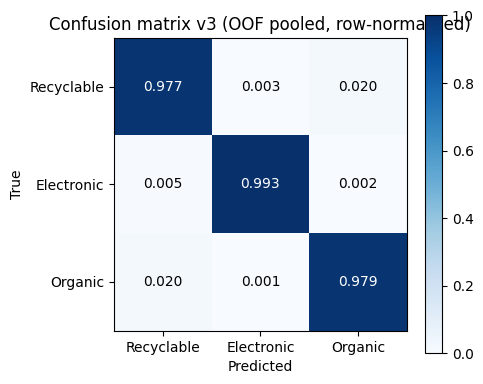

Prediksi val disimpan: /kaggle/working/experiments/v3_convnext_clean/oof_predictions.csv


In [21]:
oof_mask = ~np.isnan(oof_probs).any(axis=1)
scope = "OOF pooled" if len(CFG.TRAIN_FOLDS) == CFG.N_FOLDS else f"val fold {CFG.TRAIN_FOLDS}"
print(f"Evaluasi tersedia untuk {int(oof_mask.sum())}/{len(train_df)} baris ({scope})")
oof_pred = oof_probs[oof_mask].argmax(axis=1)
oof_true = train_df.loc[oof_mask, "label"].to_numpy()

oof_macro_f1 = f1_score(oof_true, oof_pred, average="macro")
oof_per_class = f1_score(oof_true, oof_pred, average=None, labels=list(range(CFG.NUM_CLASSES)))
print(f"\nMacro F1 ({scope}, seleksi TTA={CFG.USE_VAL_TTA}): {oof_macro_f1:.4f}")
print(f"Referensi ablation data-bersih fold 0 : {CFG.REF_ABLATION_FOLD0_NO_TTA:.4f} (tanpa TTA) / "
      f"{CFG.REF_ABLATION_FOLD0_TTA:.4f} (TTA)  [APPROXIMATE, komposisi fold beda]")
print(f"Referensi OOF pooled data asli        : v1 {CFG.REF_V1_OOF:.4f} | v2 {CFG.REF_V2_OOF:.4f}")
if len(fold_summary_df):
    r0 = fold_summary_df.iloc[0]
    print(f"Fold 0 v3: tanpa-TTA={r0['val_macro_f1_no_tta']:.4f} (vs ref {CFG.REF_ABLATION_FOLD0_NO_TTA:.4f}, "
          f"{r0['val_macro_f1_no_tta'] - CFG.REF_ABLATION_FOLD0_NO_TTA:+.4f}) | "
          f"TTA={r0['val_macro_f1_tta']:.4f} (vs ref {CFG.REF_ABLATION_FOLD0_TTA:.4f}, "
          f"{r0['val_macro_f1_tta'] - CFG.REF_ABLATION_FOLD0_TTA:+.4f})")
print()
print(classification_report(oof_true, oof_pred,
                            labels=list(range(CFG.NUM_CLASSES)),
                            target_names=[CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)], digits=4))

cm = confusion_matrix(oof_true, oof_pred, labels=list(range(CFG.NUM_CLASSES)), normalize="true")
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
tick_names = [CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)]
ax.set_xticks(range(CFG.NUM_CLASSES), tick_names)
ax.set_yticks(range(CFG.NUM_CLASSES), tick_names)
for i in range(CFG.NUM_CLASSES):
    for j in range(CFG.NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]:.3f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Confusion matrix v3 ({scope}, row-normalized)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

oof_out = train_df.loc[oof_mask, ["relpath", "class_name", "label", "fold"]].copy()
oof_out["pred"] = oof_pred
for i in range(CFG.NUM_CLASSES):
    oof_out[f"prob_{i}"] = oof_probs[oof_mask, i]
oof_out.to_csv(CFG.EXP_DIR / "oof_predictions.csv", index=False)
print("Prediksi val disimpan:", CFG.EXP_DIR / "oof_predictions.csv")

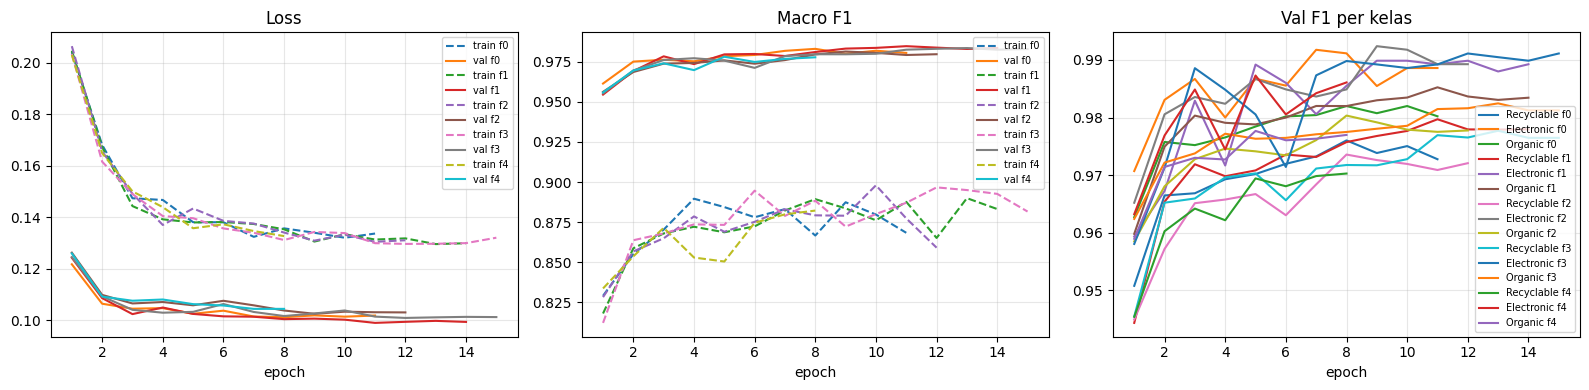

In [22]:
# Kurva training: loss dan macro F1 per epoch (+ F1 per kelas val)
hist = pd.DataFrame(history_rows)
if len(hist):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for f, g in hist.groupby("fold"):
        axes[0].plot(g["epoch"], g["train_loss"], "--", label=f"train f{f}")
        axes[0].plot(g["epoch"], g["val_loss"], "-", label=f"val f{f}")
        axes[1].plot(g["epoch"], g["train_macro_f1"], "--", label=f"train f{f}")
        axes[1].plot(g["epoch"], g["val_macro_f1"], "-", label=f"val f{f}")
        for i in range(CFG.NUM_CLASSES):
            axes[2].plot(g["epoch"], g[f"val_f1_{CFG.LABEL_NAMES[i]}"], "-",
                         label=f"{CFG.LABEL_NAMES[i]} f{f}")
    for ax, ttl in zip(axes, ["Loss", "Macro F1", "Val F1 per kelas"]):
        ax.set_xlabel("epoch")
        ax.set_title(ttl)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [23]:
# Catat hasil ke experiments/EXPERIMENTS_LOG.md (append-only, entry lama tidak boleh ditimpa)
NOTES = ("v3: ConvNeXtV2-Base fcmae_ft_in22k_in1k full fine-tune 224px pada data train BERSIH "
         "(pasca 111 relabel manual; guard versi data aktif), single model TANPA ensemble, fold fresh "
         "StratifiedKFold(5, seed 42) di data bersih. Resep: FocalLoss+WeightedSampler identik v1, "
         f"augmentasi v1 + vertical flip={CFG.USE_VFLIP}, mixup/cutmix GPU p={CFG.MIX_PROB}, "
         f"grad clip {CFG.GRAD_CLIP_NORM}, epochs {CFG.EPOCHS} patience {CFG.EARLY_STOPPING_PATIENCE}, "
         f"LLRD={'ON decay ' + str(CFG.LAYER_DECAY) if CFG.USE_LLRD else 'off (dua grup LR)'}, "
         f"greedy soup top-{CFG.SOUP_TOPK}, batch {CFG.BATCH_SIZE}x{CFG.GRAD_ACCUM_STEPS}.")

_soup_desc = ", ".join(f"fold{r.fold}: {r.winner} (single {r.best_single_no_tta:.4f} -> soup {r.soup_no_tta:.4f})"
                       for r in fold_summary_df.itertuples())
_dev_desc = (torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else str(DEVICE))
entry = f"""
## {CFG.RUN_NAME} - {date.today().isoformat()}

- Backbone            : {CFG.MODEL_ID} (timm), full fine-tune, img {CFG.IMG_SIZE} | device: {_dev_desc}
- Data                : {len(train_df)} gambar train BERSIH (guard {CFG.EXPECTED_CLASS_COUNTS}) | fold dilatih: {CFG.TRAIN_FOLDS} dari {CFG.N_FOLDS} (fold fresh, BUKAN fold v1/v2)
- Macro F1 per fold   : {", ".join(f"fold{r.fold}={r.val_macro_f1:.4f}" for r in fold_summary_df.itertuples())}
- TTA ablation (val)  : {", ".join(f"fold{r.fold}: tanpa-TTA={r.val_macro_f1_no_tta:.4f} / TTA={r.val_macro_f1_tta:.4f}" for r in fold_summary_df.itertuples())}
- Soup per fold       : {_soup_desc}
- Referensi           : ablation data-bersih fold0 {CFG.REF_ABLATION_FOLD0_NO_TTA:.4f} no-TTA / {CFG.REF_ABLATION_FOLD0_TTA:.4f} TTA (APPROXIMATE, fold beda); OOF data asli v1 {CFG.REF_V1_OOF:.4f} / v2 {CFG.REF_V2_OOF:.4f}
- Per-class F1        : {", ".join(f"{CFG.LABEL_NAMES[i]}={oof_per_class[i]:.4f}" for i in range(CFG.NUM_CLASSES))}
- Catatan             : {NOTES}
"""
print(entry)
if CFG.SMOKE_TEST:
    print(">> SMOKE_TEST aktif: entry TIDAK ditulis ke log (bukan hasil eksperimen valid).")
else:
    CFG.LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
    with open(CFG.LOG_PATH, "a", encoding="utf-8") as f:
        f.write(entry)
    print(">> Entry ditambahkan (append) ke", CFG.LOG_PATH)


## v3_convnext_clean - 2026-07-26

- Backbone            : convnextv2_base.fcmae_ft_in22k_in1k (timm), full fine-tune, img 224 | device: Tesla T4
- Data                : 26464 gambar train BERSIH (guard {'0_Recyclable': 9999, '1_Electronic': 3961, '2_Organic': 12567}) | fold dilatih: [0, 1, 2, 3, 4] dari 5 (fold fresh, BUKAN fold v1/v2)
- Macro F1 per fold   : fold0=0.9831, fold1=0.9838, fold2=0.9814, fold3=0.9835, fold4=0.9798
- TTA ablation (val)  : fold0: tanpa-TTA=0.9827 / TTA=0.9831, fold1: tanpa-TTA=0.9844 / TTA=0.9838, fold2: tanpa-TTA=0.9813 / TTA=0.9814, fold3: tanpa-TTA=0.9837 / TTA=0.9835, fold4: tanpa-TTA=0.9810 / TTA=0.9798
- Soup per fold       : fold0: single(e8) (single 0.9827 -> soup 0.9827), fold1: soup(e[10, 11]) (single 0.9843 -> soup 0.9844), fold2: single(e9) (single 0.9813 -> soup 0.9813), fold3: soup(e[13, 15]) (single 0.9834 -> soup 0.9837), fold4: soup(e[5, 8]) (single 0.9775 -> soup 0.9810)
- Referensi           : ablation data-bersih fold0 0.9847 no-TTA / 0

## 8. Generate Submission

Aturan (juknis SS4-SS5): data test **hanya** untuk prediksi akhir; kolom `id,predicted`; kode 0/1/2; urutan id persis template. Nama file memakai **kode kelompok**: `submission_SD2026040000412.csv` (konfirmasi panitia).

**Exact match test->train** (identik v1/v2): file test yang byte-identik dengan file train memakai label train langsung; legal karena murni kesamaan internal dataset kompetisi. Catatan v3: label yang dipakai adalah label PASCA-cleaning (kalau file yang match termasuk 111 yang di-relabel, label barunya yang dipakai). Near-duplicate yang bukan exact TIDAK dipakai.

Prediksi model: mean softmax semua checkpoint fold yang tersedia + TTA flip (konsisten dengan seleksi val). Submission dari run 1-fold hanya arsip eksplorasi; submission final selayaknya dari full 5-fold.

In [24]:
ckpt_prefix = "smoke_" if CFG.SMOKE_TEST else ""
ckpt_paths = sorted(CFG.EXP_DIR.glob(f"{ckpt_prefix}fold*_best.pt"))
if not CFG.SMOKE_TEST:
    ckpt_paths = [p for p in ckpt_paths if not p.name.startswith("smoke_")]
assert ckpt_paths, "Tidak ada checkpoint fold, jalankan training dulu"
print("Checkpoint dipakai:", [p.name for p in ckpt_paths])
if len(ckpt_paths) < CFG.N_FOLDS:
    print(f"PERINGATAN: baru {len(ckpt_paths)}/{CFG.N_FOLDS} fold; submission final sebaiknya memakai semua fold.")

test_infer_df = pd.DataFrame({"id": TEMPLATE_ID_ORDER})
test_infer_df["path"] = test_infer_df["id"].map(lambda i: str(test_id_to_path[i]))
assert test_infer_df["path"].notna().all()
if CFG.SMOKE_TEST:
    test_infer_df = test_infer_df.head(CFG.SMOKE_TEST_IMAGES)
    print(f"SMOKE_TEST: inference hanya {len(test_infer_df)} gambar test pertama (cek pipeline).")

# Exact match test->train via sha256 (train_df sudah unik per sha, mixed-label sudah dikeluarkan)
hash_to_label = train_df.set_index("sha256")["label"].to_dict()
relpath_to_hash = test_scan.set_index("relpath")["sha256"].to_dict()
test_infer_df["sha256"] = [relpath_to_hash.get(str(Path(p).relative_to(CFG.DATA_ROOT)))
                           for p in test_infer_df["path"]]
test_infer_df["match_label"] = test_infer_df["sha256"].map(hash_to_label)
matched_mask = test_infer_df["match_label"].notna().to_numpy()
print(f"Exact match test->train: {int(matched_mask.sum())}/{len(test_infer_df)} baris memakai label train langsung")

preds = np.full(len(test_infer_df), -1, dtype=int)
preds[matched_mask] = test_infer_df.loc[matched_mask, "match_label"].astype(int).to_numpy()

unmatched_df = test_infer_df[~matched_mask].reset_index(drop=True)


def infer_mean_probs(ckpt_list, infer_df):
    """Mean softmax lintas checkpoint (satu keluarga model); transform eval dari metadata checkpoint."""
    total = np.zeros((len(infer_df), CFG.NUM_CLASSES))
    for cp in ckpt_list:
        ckpt = torch.load(cp, map_location="cpu", weights_only=False)
        assert ckpt["model_id"] == CFG.MODEL_ID, f"{cp}: model_id {ckpt['model_id']} != {CFG.MODEL_ID}"
        assert CFG.SMOKE_TEST or not ckpt.get("smoke"), f"{Path(cp).name} berasal dari smoke run"
        _, tf_eval = build_transforms(ckpt["img_size"], tuple(ckpt["mean"]), tuple(ckpt["std"]))
        loader = DataLoader(WasteDataset(infer_df, tf_eval, with_target=False, safe_mode=True,
                                         img_size=ckpt["img_size"], max_decode_side=CFG.MAX_DECODE_SIDE),
                            batch_size=CFG.BATCH_SIZE * 2, shuffle=False, num_workers=CFG.NUM_WORKERS,
                            pin_memory=PIN_MEMORY,
                            prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
                            worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)
        model = timm.create_model(CFG.MODEL_ID, pretrained=False, num_classes=CFG.NUM_CLASSES)
        model.load_state_dict(ckpt["state_dict"])
        model = maybe_data_parallel(to_device(model))
        out = run_epoch(model, loader, use_tta=CFG.USE_VAL_TTA, desc=f"infer {Path(cp).stem}")
        total += out["probs"] / len(ckpt_list)
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return total


if len(unmatched_df):
    final_probs = infer_mean_probs(ckpt_paths, unmatched_df)
    preds[~matched_mask] = final_probs.argmax(axis=1).astype(int)

assert (preds >= 0).all()
test_infer_df["predicted"] = preds
print("\nDistribusi prediksi:")
print(test_infer_df["predicted"].value_counts().rename(index=CFG.LABEL_NAMES).to_string())

Checkpoint dipakai: ['fold0_best.pt', 'fold1_best.pt', 'fold2_best.pt', 'fold3_best.pt', 'fold4_best.pt']
Exact match test->train: 97/1458 baris memakai label train langsung
2 GPU terdeteksi; v3 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).


infer fold0_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold0_best: batch 22/22 (100%) | 1.12s/iter | RSS 6.0GB (delta +0.0GB) | VRAM 8.3GB
2 GPU terdeteksi; v3 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).


infer fold1_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold1_best: batch 22/22 (100%) | 0.81s/iter | RSS 6.0GB (delta +0.0GB) | VRAM 8.3GB
2 GPU terdeteksi; v3 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).


...

[hb] infer fold2_best: batch 22/22 (100%) | 0.82s/iter | RSS 6.0GB (delta +0.0GB) | VRAM 8.3GB
2 GPU terdeteksi; v3 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).


infer fold3_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold3_best: batch 22/22 (100%) | 0.80s/iter | RSS 6.0GB (delta +0.0GB) | VRAM 8.3GB
2 GPU terdeteksi; v3 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).


infer fold4_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold4_best: batch 22/22 (100%) | 0.82s/iter | RSS 6.0GB (delta +0.0GB) | VRAM 8.3GB

Distribusi prediksi:
predicted
Organic       734
Recyclable    523
Electronic    201


In [25]:
submission_df = test_infer_df[["id", "predicted"]].copy()

# Verifikasi keras terhadap template SEBELUM menyimpan (juknis SS4: format & urutan wajib persis)
ref = template_df.head(len(submission_df)) if CFG.SMOKE_TEST else template_df
assert list(submission_df.columns) == ["id", "predicted"], "Nama/urutan kolom tidak sesuai template"
assert len(submission_df) == len(ref), f"Jumlah baris {len(submission_df)} != template {len(ref)}"
assert (submission_df["id"].to_numpy() == ref["id"].to_numpy()).all(), "Urutan id TIDAK sama dengan template!"
assert submission_df["predicted"].isin([0, 1, 2]).all(), "predicted harus kode numerik 0/1/2"
assert submission_df["predicted"].notna().all()
print("Semua verifikasi format & urutan id LULUS.")

if CFG.SMOKE_TEST:
    print(">> SMOKE_TEST aktif: file submission TIDAK disimpan. Jalankan full run untuk membuat submission.")
else:
    sub_path = CFG.SUBMISSION_DIR / f"submission_{CFG.GROUP_CODE}.csv"
    submission_df.to_csv(sub_path, index=False)
    submission_df.to_csv(CFG.EXP_DIR / sub_path.name, index=False)  # arsip per eksperimen
    print("Submission disimpan:", sub_path)
    print("(nama file memakai KODE KELOMPOK sesuai konfirmasi panitia, bukan nama tim)")
    comp = pd.DataFrame({
        "pred_test_%": (100 * submission_df["predicted"].value_counts(normalize=True)).round(2),
        "train_%": (100 * train_df["label"].value_counts(normalize=True)).round(2),
    }).rename(index=CFG.LABEL_NAMES)
    print("\nDistribusi prediksi test vs train (sanity check):")
    display(comp)
    print("INGAT: maksimal 3 submission; keputusan submit berbasis OOF + ambang runbook (+0.002), oleh user;")
    print("submission dari run 1-fold adalah arsip eksplorasi, bukan kandidat submit.")

Semua verifikasi format & urutan id LULUS.
Submission disimpan: /kaggle/working/outputs/submission_SD2026040000412.csv
(nama file memakai KODE KELOMPOK sesuai konfirmasi panitia, bukan nama tim)

Distribusi prediksi test vs train (sanity check):


,pred_test_%,train_%
Organic,50.34,47.40
Recyclable,35.87,37.75
Electronic,13.79,14.85


INGAT: maksimal 3 submission; keputusan submit berbasis OOF + ambang runbook (+0.002), oleh user;
submission dari run 1-fold adalah arsip eksplorasi, bukan kandidat submit.


## 9. Analisis Error + Grad-CAM (fokus Recyclable<->Organic)

Dua lapis analisis:
1. **Top error by margin** (pola v1/v2): baris val dengan `p_pred - p_label` terbesar sebagai grid; kandidat antrean review label ronde berikutnya (tidak ada relabel otomatis, keputusan manusia).
2. **Grad-CAM** (baru v3, motivasi arXiv 2505.16513): pada error Recyclable<->Organic, cek apakah model menatap OBJEK atau BACKGROUND/konteks. Kalau heatmap dominan jatuh di background (meja, tanah, piring), ada shortcut yang bisa diserang dengan augmentasi crop lebih agresif di iterasi berikutnya; kalau di objek yang memang ambigu (makanan dalam kemasan), perbaikannya di definisi label/review, bukan kapasitas model.

Total error val: 519 baris

Pasangan (true -> pred) terbanyak:
class_name  pred   n  pred_name
   Organic     0 246 Recyclable
Recyclable     2 197    Organic
Recyclable     1  33 Electronic
Electronic     0  18 Recyclable
   Organic     1  17 Electronic
Electronic     2   8    Organic

Error Recyclable<->Organic: 443/519 (85.4%; pembanding v2 di data asli: 84.5%)
Top error disimpan: /kaggle/working/experiments/v3_convnext_clean/oof_top_errors.csv (input antrean review label ronde berikutnya)


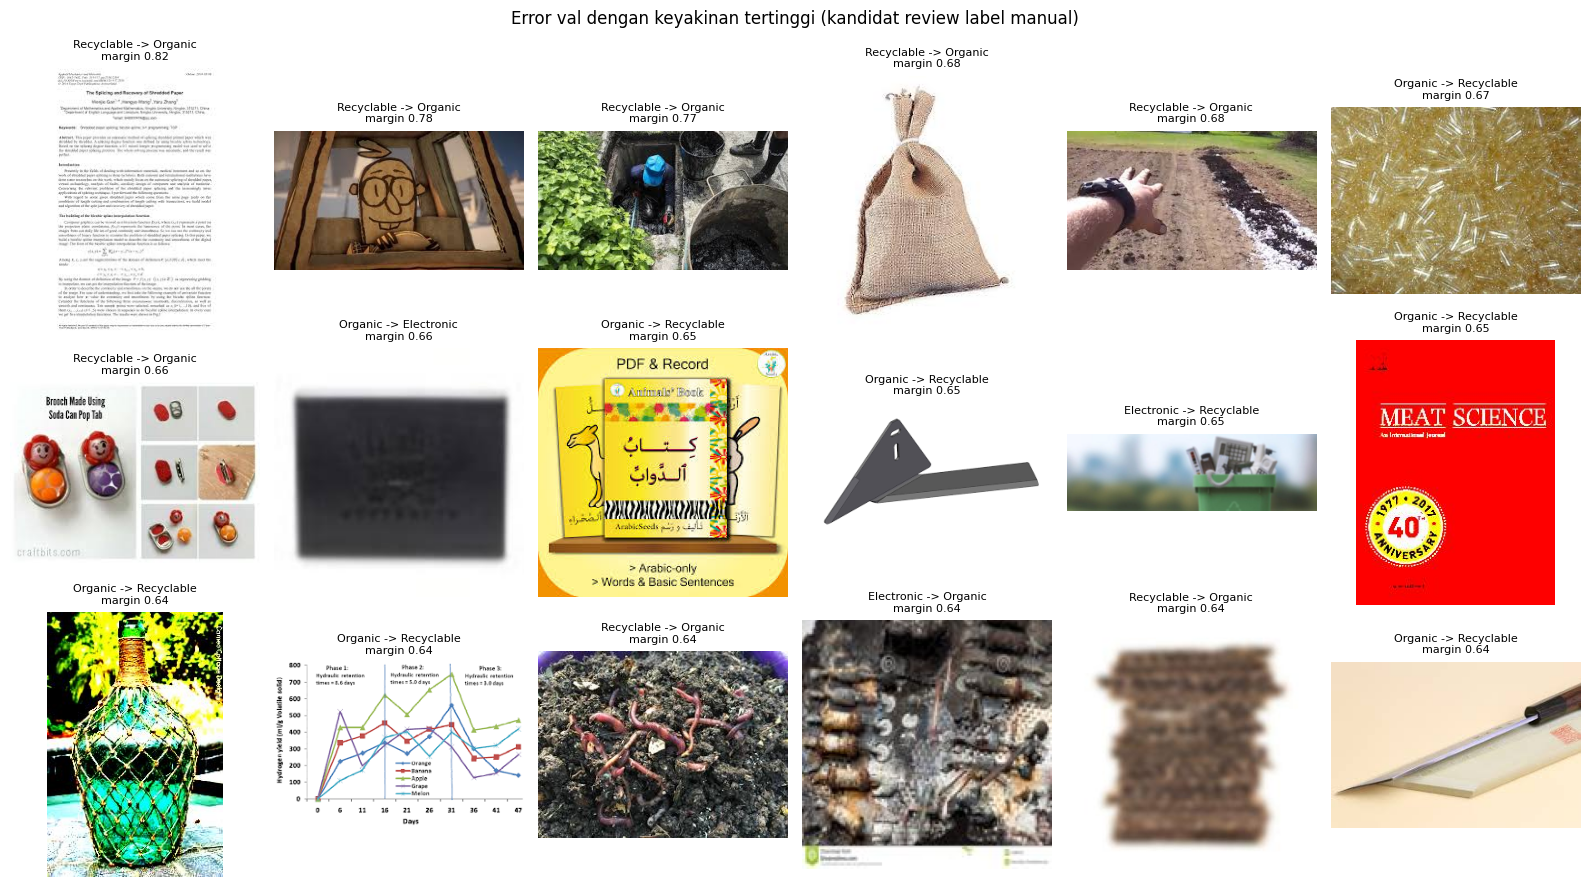

In [26]:
err = oof_out[oof_out["pred"] != oof_out["label"]].copy()
if err.empty:
    print("Tidak ada error val (subset smoke terlalu kecil / hasil sempurna).")
else:
    probs_arr = err[[f"prob_{i}" for i in range(CFG.NUM_CLASSES)]].to_numpy()
    err["p_pred"] = probs_arr[np.arange(len(err)), err["pred"].to_numpy()]
    err["p_label"] = probs_arr[np.arange(len(err)), err["label"].to_numpy()]
    err["margin"] = err["p_pred"] - err["p_label"]
    err = err.sort_values("margin", ascending=False)
    print(f"Total error val: {len(err)} baris")
    print("\nPasangan (true -> pred) terbanyak:")
    print(err.groupby(["class_name", "pred"]).size().rename("n").reset_index()
          .assign(pred_name=lambda d: d["pred"].map(CFG.LABEL_NAMES))
          .sort_values("n", ascending=False).head(6).to_string(index=False))
    ro_mask = ((err["label"] == 0) & (err["pred"] == 2)) | ((err["label"] == 2) & (err["pred"] == 0))
    print(f"\nError Recyclable<->Organic: {int(ro_mask.sum())}/{len(err)} "
          f"({100 * ro_mask.mean():.1f}%; pembanding v2 di data asli: 84.5%)")
    err.head(200).to_csv(CFG.EXP_DIR / "oof_top_errors.csv", index=False)
    print("Top error disimpan:", CFG.EXP_DIR / "oof_top_errors.csv (input antrean review label ronde berikutnya)")

    n_show = min(18, len(err))
    path_by_relpath = train_df.set_index("relpath")["path"].to_dict()
    fig, axes = plt.subplots(3, 6, figsize=(16, 9))
    for ax, (_, r) in zip(axes.flat, err.head(n_show).iterrows()):
        try:
            img = Image.open(path_by_relpath[r["relpath"]])
            img.draft("RGB", (512, 512))
            ax.imshow(ImageOps.exif_transpose(img).convert("RGB"))
        except Exception:
            pass
        ax.set_title(f"{r['class_name']} -> {CFG.LABEL_NAMES[int(r['pred'])]}\nmargin {r['margin']:.2f}", fontsize=8)
        ax.axis("off")
    for ax in axes.flat[n_show:]:
        ax.axis("off")
    plt.suptitle("Error val dengan keyakinan tertinggi (kandidat review label manual)")
    plt.tight_layout()
    plt.show()

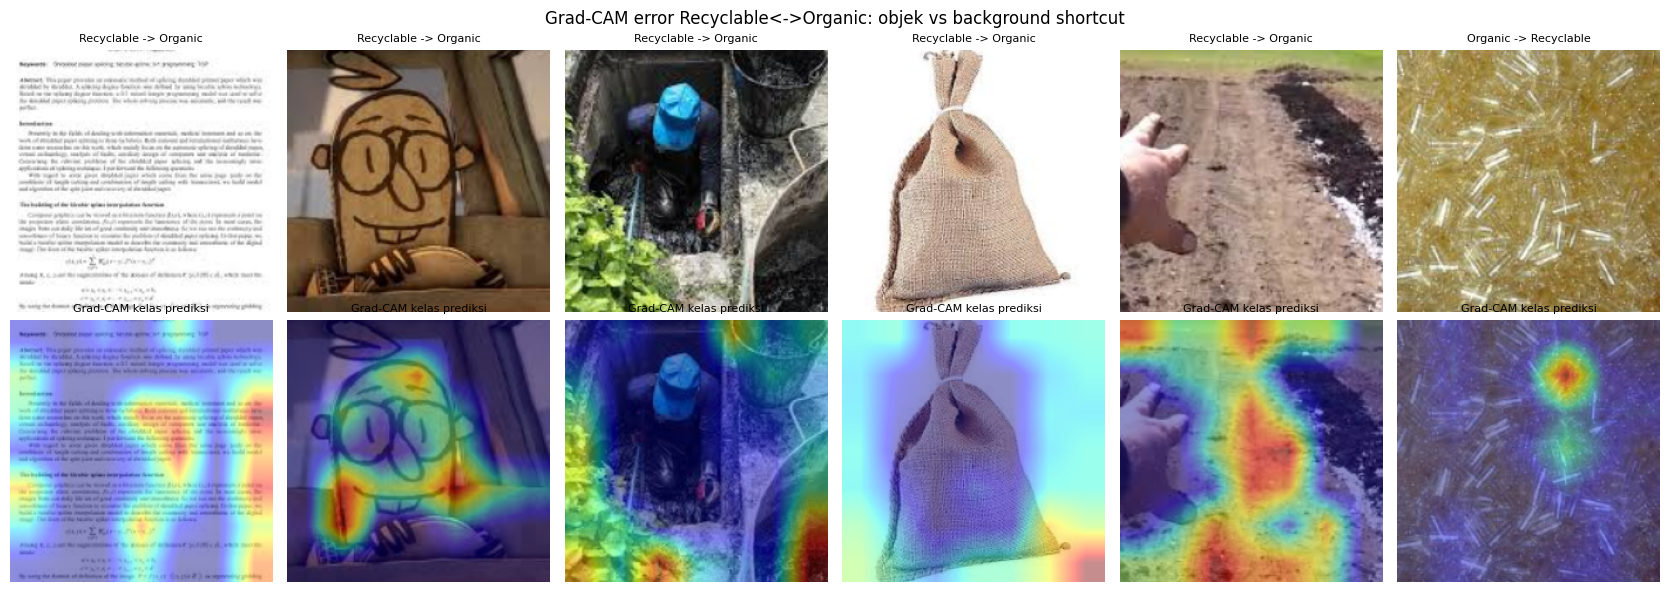

In [27]:
# Grad-CAM pada error Recyclable<->Organic teratas: model menatap objek atau background?
def grad_cam(model, pil_img, target_class):
    """Grad-CAM standar pada stage terakhir ConvNeXtV2 (aktivasi spasial 7x7). fp32, tanpa autocast."""
    model.eval()
    acts, grads = [], []
    layer = unwrap(model).stages[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: acts.append(o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.append(go[0]))
    try:
        x = eval_transform(pil_img).unsqueeze(0).to(DEVICE)
        logits = model(x)
        model.zero_grad(set_to_none=True)
        logits[0, target_class].backward()
    finally:
        h1.remove()
        h2.remove()
    a, g = acts[0][0].detach(), grads[0][0].detach()
    w = g.mean(dim=(1, 2), keepdim=True)
    cam = torch.relu((w * a).sum(0)).float().cpu().numpy()
    cam = cam / (cam.max() + 1e-8)
    return np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((CFG.IMG_SIZE, CFG.IMG_SIZE),
                                                                          Image.Resampling.BILINEAR)) / 255.0


if not err.empty:
    ro_err = err[ro_mask].head(6)
    if ro_err.empty:
        ro_err = err.head(6)
        print("Tidak ada error R<->O; Grad-CAM memakai top error umum.")
    ckpt = torch.load(ckpt_paths[0], map_location="cpu", weights_only=False)
    cam_model = timm.create_model(CFG.MODEL_ID, pretrained=False, num_classes=CFG.NUM_CLASSES)
    cam_model.load_state_dict(ckpt["state_dict"])
    cam_model = to_device(cam_model)

    fig, axes = plt.subplots(2, len(ro_err), figsize=(2.8 * len(ro_err), 6), squeeze=False)
    disp_tf = transforms.Compose([transforms.Resize(int(CFG.IMG_SIZE * 1.14)),
                                  transforms.CenterCrop(CFG.IMG_SIZE)])
    for j, (_, r) in enumerate(ro_err.iterrows()):
        img = Image.open(path_by_relpath[r["relpath"]])
        img.draft("RGB", (1024, 1024))
        img = ImageOps.exif_transpose(img).convert("RGB")
        base = disp_tf(img)
        cam = grad_cam(cam_model, img, int(r["pred"]))
        axes[0, j].imshow(base)
        axes[0, j].set_title(f"{r['class_name']} -> {CFG.LABEL_NAMES[int(r['pred'])]}", fontsize=8)
        axes[1, j].imshow(base)
        axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
        axes[1, j].set_title(f"Grad-CAM kelas prediksi", fontsize=8)
        for i in (0, 1):
            axes[i, j].axis("off")
    plt.suptitle("Grad-CAM error Recyclable<->Organic: objek vs background shortcut")
    plt.tight_layout()
    plt.show()
    del cam_model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

> ### Insights
> Cara membaca hasil di atas untuk memutuskan langkah berikutnya:
> - **Heatmap di objek, objek memang ambigu** (makanan dalam kemasan, kayu vs kardus): sisa error adalah batas semantik label; perbaikan termurah = ronde review label berikutnya dari `oof_top_errors.csv`, bukan menambah kapasitas model (konsisten dengan review industrial-grade waste: annotator pun tidak sepakat di kelas berbatas material).
> - **Heatmap di background** (meja, lantai, piring): ada shortcut; kandidat serangan = RandomResizedCrop scale lebih agresif atau crop-to-object; uji sebagai run terpisah.
> - **Label folder jelas salah**: masukkan antrean review (append `review_queue.csv`), JANGAN relabel otomatis.

## Catatan Operasional (Alienware, Windows)

**Checklist run nyata (run A, default):**
1. Sinkronkan folder project ke Alienware; pastikan `train/` adalah versi BERSIH (guard versi data akan memverifikasi 10078/3968/12481 dan fail-fast kalau bukan).
2. `CFG.SMOKE_TEST = False`, jalankan seluruh notebook dari root project (VSCode/Jupyter, Run All). Butuh internet hanya bila bobot pretrained belum pernah diunduh di mesin itu.
3. Pantau heartbeat awal: `s/iter`, `VRAM` (harus < ~7.5GB di GPU 8GB; kalau OOM: `BATCH_SIZE=8`, `GRAD_ACCUM_STEPS=4`), dan delta RSS (harus mendekati konstan; kalau naik linear hentikan, pola debug v1).
4. Proyeksi runtime fold 0 di RTX 3070 Ti (perkiraan, verifikasi dari heartbeat): batch 16 -> ~1.330 iter/epoch; pada 0.20-0.35 s/iter kira-kira 6-10 menit/epoch + validasi; 15 epoch dengan early stop ~13 epoch = sekitar 2-3 jam + soup (~5 pass validasi) + inference.
5. Kalau `NUM_WORKERS=8` bermasalah di Windows (hang saat spawn): turunkan ke 4 atau 2; `bdc_lib_v3.py` harus ada di folder yang sama (dibuat otomatis oleh cell `%%writefile`).

**Protokol eksplorasi (satu perubahan per run, keputusan berbasis val fold 0):**
- Run A (default): resep di atas. Baseline pembanding 0.9847/0.9839 (approximate).
- Run B: `CFG.USE_LLRD = True` (ganti `RUN_NAME` misal `v3_convnext_llrd` supaya artefak tidak saling timpa).
- Run C (opsional): `CFG.USE_VFLIP = False` kalau ingin isolasi kontribusi vflip; atau `MIX_PROB = 0` untuk isolasi mixup.
- Pembacaan: perubahan diadopsi bila val F1 fold 0 naik jelas (>= +0.002, di atas noise antar-fold); kalau beda tipis, netral = pertahankan resep lebih sederhana.

**Jalan ke submission (keputusan user, bukan notebook):**
1. Resep terbaik dari eksplorasi fold 0 -> full run `TRAIN_FOLDS=[0,1,2,3,4]` (bisa dicicil [0,1,2] lalu [3,4]; OOF digabung otomatis lewat `oof_predictions.csv` per run bila fold sama) -> OOF pooled 5-fold.
2. Kandidat layak submit bila OOF pooled >= acuan + 0.002 (runbook). Konteks acuan: kandidat ensemble v1+v2 yang sudah siap = 0.9840 di data asli; angka OOF v3 di data bersih tidak persis apples-to-apples dengan itu (data beda), pertimbangkan keduanya secara strategis, 3 jatah submission.
3. Opsional sebelum submit final (pola ver34): retrain 100% data train dengan epoch terkunci dari hasil 5-fold; keputusan ini butuh run terpisah dan tetap satu model.

## Referensi

- arXiv 2503.02241 (DECMCV): ConvNeXt encoding unggul atas ViT pada 2 dataset waste; dasar keluarga arsitektur.
- arXiv 2602.10500 (Garbage benchmark, T4): arsitektur >> resolusi; 384px gain <1%; dasar bertahan di 224px.
- arXiv 2603.02181 (model soups ICH): greedy soup antar-checkpoint satu run, +0.4-0.9 poin di rezim noisy, biaya inferensi tetap satu model; resep grad clip 1.0.
- arXiv 2604.09697 (TTA is Not Better): TTA bisa merugikan; mekanisme utamanya (BatchNorm, resolusi 28px) tidak berlaku untuk ConvNeXtV2 224px, tapi ablation TTA per fold tetap wajib; TTA dibatasi hflip (transformasi yang ada di distribusi training).
- Sayem et al., NCA 2025 (s00521-024-10855-2, WaRP): augmentasi h+v flip valid untuk domain waste (tanpa orientasi kanonik); dual-stream mereka = ensemble, tidak diadopsi.
- arXiv 2505.16513 (Optic plastics): model sortir belajar bentuk/warna/background, bukan material; dasar audit Grad-CAM.
- arXiv 2507.01347 (GTTA): varian distillation = test-time adaptation, ILEGAL di juknis SS5; tidak diadopsi.
- arXiv 2606.25784 (S2-FracMix): tidak diadopsi (gain utama di robustness, dependensi library fraktal eksternal).
- `ref/ver34_clean_end_to_end.ipynb`, `ref/findit-v17.ipynb`: pola struktural notebook single-model finalis; pola dua tahap val-select lalu full-retrain (kandidat langkah final).
- Riwayat internal: EXPERIMENTS_LOG (v1 0.9818, v2 0.9830, ablation data bersih fold0 0.9847/0.9839), CONTEXT.md Bagian 3-5.